# Pacific North West Wildfires and Biodiversity 

## 1. Project Description

### 1.1 Data Source

### 1.2 Load and explore data

In [9]:
import sys

print(sys.executable)

/opt/anaconda3/envs/wildfires/bin/python


In [10]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("GeoPandas:", gpd.__version__)

Pandas: 3.0.6
NumPy: 2.5.4
GeoPandas: 1.2.0


### 1.3 Uploadind CA, OR, and WA wildfire data sets

In [12]:
CA = pd.read_csv("/Users/marianabutarov/Data_Science/Wildfire/Data/California_Fire.csv")
OR = pd.read_csv("/Users/marianabutarov/Data_Science/Wildfire/Data/Oregon_Fire.csv")
WA = pd.read_csv("/Users/marianabutarov/Data_Science/Wildfire/Data/Washington_Fire.csv")

/var/folders/j1/t6wf96vj4hq1p8zg7blqq7km0000gn/T/ipykernel_63113/2356313499.py:2: DtypeWarning: Columns (7: ComplexName, 10: EstTotalAcres, 11: ODF_Protected_Acres) have mixed types. Specify dtype option on import or set low_memory=False.
  OR = pd.read_csv("/Users/marianabutarov/Data_Science/Wildfire/Data/Oregon_Fire.csv")


#### Exploring CA data set

In [14]:
CA.info()

<class 'pandas.DataFrame'>
RangeIndex: 23334 entries, 0 to 23333
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   OBJECTID                      23334 non-null  int64  
 1   Year                          23257 non-null  float64
 2   State                         23334 non-null  str    
 3   Agency                        23286 non-null  str    
 4   Unit ID                       23274 non-null  str    
 5   Fire Name                     16679 non-null  str    
 6   Local Incident Number         22379 non-null  str    
 7   IRWIN ID                      3633 non-null   str    
 8   Alarm Date                    17950 non-null  str    
 9   Containment Date              10716 non-null  str    
 10  Cause                         23334 non-null  int64  
 11  Collection Method             23334 non-null  int64  
 12  Management Objective          23063 non-null  float64
 13  GIS Calculat

In [15]:
CA.head()

,OBJECTID,Year,State,Agency,Unit ID,Fire Name,Local Incident Number,IRWIN ID,Alarm Date,Containment Date,...,Management Objective,GIS Calculated Acres,Comments,Complex Name,Complex ID,Fire Number (historical use),GlobalID,Decade,Shape__Area,Shape__Length
0,1,2025.0,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},8/1/2025 12:00:00 AM,10/14/2025 12:00:00 AM,...,1.0,131613.50,NaN,NaN,NaN,NaN,e87207ff-bd3d-4836-8a89-ad218a20b17e,2020-2025,7.981293e+08,315035.257689
1,2,2025.0,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},7/2/2025 12:00:00 AM,7/26/2025 12:00:00 AM,...,1.0,80779.10,NaN,NaN,NaN,NaN,c59c71e2-f79f-440b-8c84-48058988f3cf,2020-2025,4.896913e+08,234788.870249
2,3,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},8/24/2025 12:00:00 AM,10/23/2025 12:00:00 AM,...,1.0,60019.23,NaN,NaN,NaN,NaN,ddd0b278-7655-4f20-829d-feeef1dc935f,2020-2025,3.810198e+08,293948.428196
3,4,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},9/2/2025 12:00:00 AM,9/17/2025 12:00:00 AM,...,1.0,25553.55,Park incident clipped out per BEU,NaN,NaN,NaN,6817a72c-90cf-4cd4-8f26-2b9622f1f140,2020-2025,1.582992e+08,111440.092841
4,5,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},1/7/2025 12:00:00 AM,1/31/2025 12:00:00 AM,...,1.0,23448.88,NaN,NaN,NaN,NaN,73730f90-5d60-4850-98c2-2431c4284cd7,2020-2025,1.386518e+08,140231.608232


In [16]:
CA['GlobalID'].is_unique

True

#### Exploring OR data set

In [18]:
OR.info()

<class 'pandas.DataFrame'>
RangeIndex: 26817 entries, 0 to 26816
Data columns (total 39 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Serial                  26817 non-null  int64  
 1   FireCategory            26817 non-null  str    
 2   FireYear                26817 non-null  int64  
 3   Area                    26817 non-null  str    
 4   DistrictName            26817 non-null  str    
 5   UnitName                26817 non-null  str    
 6   FullFireNumber          26817 non-null  str    
 7   ComplexName             177 non-null    str    
 8   FireName                26817 non-null  str    
 9   Size_class              26817 non-null  str    
 10  EstTotalAcres           26716 non-null  object 
 11  ODF_Protected_Acres     26817 non-null  object 
 12  HumanOrLightning        26817 non-null  str    
 13  CauseBy                 26643 non-null  str    
 14  GeneralCause            26815 non-null  str    
 

In [19]:
OR.head()

,Serial,FireCategory,FireYear,Area,DistrictName,UnitName,FullFireNumber,ComplexName,FireName,Size_class,...,Industrial_Restriction,Ign_DateTime,ReportDateTime,Discover_DateTime,Control_DateTime,CreationDate,ModifiedDate,DistrictCode,UnitCode,DistFireNumber
0,96127,STAT,2014,NOA,North Cascade,Santiam,14-582046-14,1-2-3 COMPLEX,1-2-3 COMPLEX (K200),E,...,Outside Closed Fire Season,2014 Jan 23 05:00:00 AM,2014 Jan 23 09:51:00 AM,2014 Jan 23 09:51:00 AM,2014 Jan 25 05:00:00 PM,2014 Jan 27 12:00:00 AM,2014 May 09 03:15:00 PM,58,582,46
1,77291,STAT,2007,SOA,Southwest Oregon,Medford,07-711168-07,6/2 Complex,6/2 Complex Millmar,A,...,Outside Closed Fire Season,2007 Jun 02 01:00:00 AM,2007 Jun 02 10:00:00 AM,2007 Jun 02 09:50:00 AM,2007 Jun 02 01:00:00 PM,2007 Jun 04 10:21:00 AM,2007 Oct 15 01:14:00 PM,71,711,168
2,80224,STAT,2008,SOA,Southwest Oregon,Medford,08-711196-08,6/21 Complex,6/21 Complex,B,...,Lvl 1 Fire Season Only,2008 Jun 21 06:00:00 AM,2008 Jun 21 07:03:00 AM,2008 Jun 21 07:03:00 AM,2008 Jun 21 05:00:00 PM,2008 Jun 21 12:00:00 AM,2008 Jun 30 06:12:00 PM,71,711,196
3,80350,STAT,2008,SOA,Southwest Oregon,Medford,08-711206-08,6/28 Complex,6/28 Complex - Duggan,A,...,Lvl 1 Fire Season Only,2008 Jun 28 07:29:00 PM,2008 Jun 28 07:33:00 PM,2008 Jun 28 07:32:00 PM,2008 Jun 28 09:30:00 PM,2008 Jun 29 12:00:00 AM,2008 Jun 29 11:34:00 AM,71,711,206
4,74479,STAT,2006,SOA,Southwest Oregon,Medford,06-711144-06,6/29 Complex,Sandbar (6/29 Complex),A,...,Lvl 1 Fire Season Only,2006 Jun 29 06:26:00 PM,2006 Jun 29 06:30:00 PM,2006 Jun 29 06:28:00 PM,2006 Jun 29 10:30:00 PM,2006 Jun 29 09:31:00 PM,2006 Oct 03 09:33:00 AM,71,711,144


In [20]:
OR['FullFireNumber'].is_unique

False

In [21]:
OR['FullFireNumber'].duplicated().sum()

np.int64(287)

In [22]:
OR.duplicated().sum()

np.int64(0)

In [23]:
OR[OR["FullFireNumber"].duplicated(keep=False)].sort_values("FullFireNumber")

,Serial,FireCategory,FireYear,Area,DistrictName,UnitName,FullFireNumber,ComplexName,FireName,Size_class,...,Industrial_Restriction,Ign_DateTime,ReportDateTime,Discover_DateTime,Control_DateTime,CreationDate,ModifiedDate,DistrictCode,UnitCode,DistFireNumber
17599,58267,STAT,2000,EOA,Central Oregon,John Day,00-952018-01,NaN,Fisher Creek,A,...,Does Not Apply - Eastern OR,2000 Jul 19 08:00:00 PM,2000 Jul 20 11:47:00 AM,2000 Jul 20 11:40:00 AM,2000 Jul 20 02:20:00 PM,2000 Jul 20 02:29:00 PM,2000 Nov 14 09:37:00 AM,95,952,18
6843,58189,STAT,2000,EOA,Central Oregon,John Day,00-952018-01,NaN,Rob Springs,B,...,Does Not Apply - Eastern OR,2000 Jul 18 06:30:00 PM,2000 Jul 18 06:30:00 PM,2000 Jul 18 06:30:00 PM,2000 Jul 19 07:23:00 PM,2000 Jul 18 07:13:00 PM,2004 Sep 19 10:59:00 AM,95,952,18
746,58374,STAT,2000,EOA,Central Oregon,John Day,00-952025-01,NaN,Shaw Creek,D,...,Does Not Apply - Eastern OR,2000 Jul 24 02:00:00 PM,2000 Jul 24 02:58:00 PM,2000 Jul 24 02:38:00 PM,2000 Jul 26 08:00:00 AM,2000 Jul 24 11:39:00 PM,2001 Mar 06 09:05:00 AM,95,952,25
4120,58218,STAT,2000,EOA,Central Oregon,John Day,00-952025-01,NaN,Slick Ear,B,...,Does Not Apply - Eastern OR,2000 Jul 18 04:00:00 PM,2000 Jul 19 12:30:00 PM,2000 Jul 19 12:08:00 PM,2000 Jul 19 06:26:00 PM,2000 Jul 19 02:20:00 PM,2000 Nov 15 03:52:00 PM,95,952,25
6826,59434,STAT,2000,EOA,Central Oregon,John Day,00-952043-01,NaN,Harrison Creek,B,...,Does Not Apply - Eastern OR,2000 Sep 04 08:00:00 PM,2000 Sep 07 02:53:00 PM,2000 Sep 07 02:53:00 PM,2000 Sep 07 07:00:00 PM,2000 Sep 07 03:32:00 PM,2000 Oct 23 11:31:00 AM,95,952,43
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26804,133704,STAT,2022,EOA,Klamath-Lake,Lakeview,22-982030-23,NaN,White Rock 396,A,...,Not Found,NaN,2022-10-10T10:47:00.000,NaN,NaN,2022-10-11T00:00:00.000,2022-10-11T12:00:00.000,98,982,030
26802,133484,STAT,2022,EOA,Walker Range,Walker Range,22-991226-23,NaN,Reservior,A,...,Not Found,NaN,2022-10-03T07:26:00.000,NaN,NaN,2022-10-03T00:00:00.000,2022-10-03T08:43:00.000,99,991,226
26723,133484,STAT,2022,EOA,Walker Range - WRFPA,Crescent,22-991226-23,NaN,Reservior,A,...,NaN,NaN,2022 Oct 03 07:26:00 AM,NaN,NaN,2022 Oct 03 12:00:00 AM,2022 Oct 03 08:43:00 AM,99,991,226
16360,145380,STAT,2025,EOA,Central Oregon,Not Found,25-953022-26,NaN,PRICE CANYON 259,A,...,Does Not Apply - Eastern Oregon,2025-09-08T17:01:00.000,2025-09-09T11:44:00.000,2025-09-09T11:44:00.000,2025-09-09T14:02:00.000,2025-09-09T00:00:00.000,2025-09-25T10:59:00.000,95,953,022


In [24]:
counts = OR.groupby(
    "FullFireNumber", dropna=False
).cumcount()

mask = counts > 0

OR.loc[mask, "FullFireNumber"] = (
    OR.loc[mask, "FullFireNumber"].astype("string")
    + "-"
    + counts[mask].astype("string")
)

In [25]:
print("Total records:", len(OR))
OR["FullFireNumber"].is_unique

Total records: 26817


True

#### Exploring WA data set

In [27]:
WA.info()

<class 'pandas.DataFrame'>
RangeIndex: 30521 entries, 0 to 30520
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   X                             30521 non-null  int64  
 1   Y                             30521 non-null  int64  
 2   OBJECTID                      30521 non-null  int64  
 3   FIREEVENT_ID                  28741 non-null  float64
 4   INCIDENT_NO                   21571 non-null  float64
 5   INCIDENT_NM                   30521 non-null  str    
 6   INCIDENT_ID                   30521 non-null  int64  
 7   COUNTY_LABEL_NM               30521 non-null  str    
 8   FIRE_TWP_WHOLE_NO             30521 non-null  int64  
 9   FIRE_TWP_FRACT_NO             30521 non-null  int64  
 10  FIRE_RGE_WHOLE_NO             30521 non-null  int64  
 11  FIRE_RGE_FRACT_NO             30521 non-null  int64  
 12  FIRE_RGE_DIR_FLG              30521 non-null  str    
 13  FIRE_SECT_NO

In [28]:
WA.head()

,X,Y,OBJECTID,FIREEVENT_ID,INCIDENT_NO,INCIDENT_NM,INCIDENT_ID,COUNTY_LABEL_NM,FIRE_TWP_WHOLE_NO,FIRE_TWP_FRACT_NO,...,SECTION_SUBDIV_PTS_ID,LAT_COORD,LON_COORD,RES_ORDER_NO,NON_DNR_RES_ORDER_NO,START_OWNER_AGENCY_NM,START_JURISDICTION_AGENCY_NM,PROTECTION_TYPE,REGION_NAME,DSCVR_MONTH
0,1811071,1159137,1,49996.0,26.0,LITTLE PEACOCK,49829,OKANOGAN,35,0,...,662491,48.509150,-119.796370,NaN,NaN,DNR,DNR,DNR Protection FFPA,NORTHEAST,MAY
1,1534418,208728,2,50035.0,7.0,TURKEY RANCH,49868,KLICKITAT,5,0,...,372894,45.904947,-120.916377,WA-SES-050,NaN,Private,DNR,DNR Protection FFPA,SOUTHEAST,MAY
2,1534418,208728,3,68515.0,10.0,MILL CREEK,68408,KLICKITAT,5,0,...,372894,45.904947,-120.916377,WA-SES-2021-0047,WA-SES-2021-0047,Private,DNR,DNR Protection FFPA,SOUTHEAST,APRIL
3,1534418,208728,4,84502.0,NaN,JACKNIFE BUTTE,85944,KLICKITAT,5,0,...,372894,45.904947,-120.916377,WA-SES-2025-0120,NaN,Private,DNR,DNR Protection FFPA,SOUTHEAST,MAY
4,1534418,208728,5,84775.0,NaN,NO NAME SPRING,86210,KLICKITAT,5,0,...,372894,45.904947,-120.916377,WA-SES-2025-0158,NaN,Private,WA Fire Service,Threat To DNR Protection FFPA Land,SOUTHEAST,MAY


In [29]:
WA["INCIDENT_ID"].is_unique

True

In [30]:
WA["INCIDENT_ID"].is_unique

True

After exploring the columns and data types of each dataset, we decided which columns would be most relevant to our project. We also noticed that the California dataset was missing some information we needed, so we had to explore additional datasets and merge the relevant information.

The following columns were selected from each dataset:

- **California:** `GlobalID`, `Alarm Date`, `Cause`, `State`, and `GIS Calculated Acres`.
- **Oregon:** `FullFireNumber`, `Discover_DateTime`, `County`, `GeneralCause`, `Lat_DD`, `Long_DD`, and `EstTotalAcres`.
- **Washington:** `INCIDENT_ID`, `DSCVR_DT`, `COUNTY_LABEL_NM`, `FIREGCAUSE_LABEL_NM`, `LAT_COORD`, `LON_COORD`, and `ACRES_BURNED`.

For the California dataset, we needed to add three additional columns: **longitude, latitude, and county**. This required using additional geographic data to identify the locations of the wildfires.

For the Oregon and Washington datasets, we added a **state** column to identify which state each wildfire occurred in.

These changes were necessary to make the three datasets more consistent and prepare them for merging into a single dataset for our analysis.

### 1.4 Uploading aditional data sets for California

In [33]:
california = gpd.read_file("/Users/marianabutarov/Data_Science/Wildfire/Data/California_Historic_Fire_Perimeters_-4891938132824355098.geojson")
california.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 23334 entries, 0 to 23333
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   OBJECTID      23334 non-null  int32   
 1   YEAR_         23257 non-null  float64 
 2   STATE         23334 non-null  str     
 3   AGENCY        23286 non-null  str     
 4   UNIT_ID       23274 non-null  str     
 5   FIRE_NAME     16751 non-null  str     
 6   INC_NUM       22379 non-null  str     
 7   IRWINID       3634 non-null   str     
 8   ALARM_DATE    17950 non-null  str     
 9   CONT_DATE     10716 non-null  str     
 10  CAUSE         23334 non-null  int32   
 11  C_METHOD      23334 non-null  int32   
 12  OBJECTIVE     23063 non-null  float64 
 13  GIS_ACRES     23334 non-null  float64 
 14  COMMENTS      2962 non-null   str     
 15  COMPLEX_NAME  618 non-null    str     
 16  COMPLEX_ID    585 non-null    str     
 17  FIRE_NUM      17640 non-null  str     
 18

In [34]:
california.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,...,C_METHOD,OBJECTIVE,GIS_ACRES,COMMENTS,COMPLEX_NAME,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,geometry
0,1,2025.0,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},"Fri, 01 Aug 2025 00:00:00 GMT","Tue, 14 Oct 2025 00:00:00 GMT",...,3,1.0,131613.50,NaN,NaN,NaN,NaN,e87207ff-bd3d-4836-8a89-ad218a20b17e,2020-2025,"MULTIPOLYGON (((-13401376.178 4203562.931, -13..."
1,2,2025.0,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},"Wed, 02 Jul 2025 00:00:00 GMT","Sat, 26 Jul 2025 00:00:00 GMT",...,7,1.0,80779.10,NaN,NaN,NaN,NaN,c59c71e2-f79f-440b-8c84-48058988f3cf,2020-2025,"POLYGON ((-13363729.916 4190093.666, -13363730..."
2,3,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},"Sun, 24 Aug 2025 00:00:00 GMT","Thu, 23 Oct 2025 00:00:00 GMT",...,3,1.0,60019.23,NaN,NaN,NaN,NaN,ddd0b278-7655-4f20-829d-feeef1dc935f,2020-2025,"MULTIPOLYGON (((-13246213.777 4426752.325, -13..."
3,4,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},"Tue, 02 Sep 2025 00:00:00 GMT","Wed, 17 Sep 2025 00:00:00 GMT",...,7,1.0,25553.55,Park incident clipped out per BEU,NaN,NaN,NaN,6817a72c-90cf-4cd4-8f26-2b9622f1f140,2020-2025,"POLYGON ((-13397839.121 4293483.6, -13397810.1..."
4,5,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},"Tue, 07 Jan 2025 00:00:00 GMT","Fri, 31 Jan 2025 00:00:00 GMT",...,7,1.0,23448.88,NaN,NaN,NaN,NaN,73730f90-5d60-4850-98c2-2431c4284cd7,2020-2025,"MULTIPOLYGON (((-13193558.265 4032826.468, -13..."


In [35]:
counties = gpd.read_file("/Users/marianabutarov/Data_Science/Wildfire/Data/California_County_Boundaries_and_Identifiers_Blue_Version_view_5222979114348197495.geojson")
counties.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   OBJECTID           58 non-null     int32   
 1   CDTFA_COUNTY       58 non-null     str     
 2   CDTFA_COPRI        58 non-null     str     
 3   CENSUS_PLACE_NAME  58 non-null     str     
 4   CENSUS_GEOID       58 non-null     str     
 5   CENSUS_PLACE_TYPE  58 non-null     str     
 6   GNIS_PLACE_NAME    58 non-null     str     
 7   GNIS_ID            57 non-null     float64 
 8   CDT_COUNTY_ABBR    58 non-null     str     
 9   PRIMARY_DOMAIN     0 non-null      object  
 10  CENSUS_POPULATION  0 non-null      object  
 11  CDT_NAME_SHORT     58 non-null     str     
 12  OFFSHORE           0 non-null      object  
 13  AREA_SQMI          58 non-null     float64 
 14  GlobalID           58 non-null     str     
 15  geometry           58 non-null     geometry
dtypes:

In [36]:
counties.head()

,OBJECTID,CDTFA_COUNTY,CDTFA_COPRI,CENSUS_PLACE_NAME,CENSUS_GEOID,CENSUS_PLACE_TYPE,GNIS_PLACE_NAME,GNIS_ID,CDT_COUNTY_ABBR,PRIMARY_DOMAIN,CENSUS_POPULATION,CDT_NAME_SHORT,OFFSHORE,AREA_SQMI,GlobalID,geometry
0,244,Alameda County,01000,Alameda County,06001,County,Alameda County,1675839.0,ALA,None,None,Alameda,None,746.727264,d99a13af-9851-4a4d-a926-9df7d5398bc8,"POLYGON ((-136862.653 -21116.482, -136862.975 ..."
1,245,Alpine County,02000,Alpine County,06003,County,Alpine County,1675840.0,ALP,None,None,Alpine,None,743.406638,2f9081f0-a1db-4c3d-a0c2-04d8106705a0,"POLYGON ((35904.446 77650.345, 35916.626 77625..."
2,246,Amador County,03000,Amador County,06005,County,Amador County,1675841.0,AMA,None,None,Amador,None,606.008407,0156fa03-c031-4163-b1df-baf0c1603ca5,"POLYGON ((-6292.983 76302.406, -6296.823 74295..."
3,247,Butte County,04000,Butte County,06007,County,Butte County,1675842.0,BUT,None,None,Butte,None,1677.815777,1298d058-77c7-4fa0-aced-3440f42eed40,"POLYGON ((-92396.332 176240.347, -92655.136 17..."
4,248,Calaveras County,05000,Calaveras County,06009,County,Calaveras County,1675885.0,CAL,None,None,Calaveras,None,1035.546618,e63c199c-df84-40ea-99eb-225b07008b34,"POLYGON ((-1744.777 46376.992, -1748.283 46367..."


### 1.5 Extracting counties, longitude and latitude from a geojson file 

In [38]:
fires_geo = california.to_crs(epsg=3310).copy()

counties_geo = counties[
    ["CDT_NAME_SHORT", "geometry"]
].to_crs(epsg=3310)

print("Fire CRS:", fires_geo.crs)
print("County CRS:", counties_geo.crs)
print("Number of fires:", len(fires_geo))

Fire CRS: EPSG:3310
County CRS: EPSG:3310
Number of fires: 23334


Before identifying which county each wildfire occurred in, we converted both the California wildfire and county datasets to the same coordinate reference system (EPSG:3310). This is important because we need both datasets to use the same coordinates to compare their geographic locations and calculate overlapping areas.

For the county dataset, we kept only the county name and geometry columns, since those are the ones we need. We did not need to specify the geometry column for the wildfire dataset because GeoPandas already recognizes it automatically.

Finally, we checked the coordinate systems and the number of wildfire records to make sure everything was converted correctly without losing any data.

In [40]:
fire_county_areas = gpd.overlay(
    fires_geo[["GlobalID", "geometry"]],
    counties_geo,
    how="intersection",
    keep_geom_type=False
)

fire_county_areas["Overlap_Area"] = (
    fire_county_areas.geometry.area
)

print("Fire-county intersections:", len(fire_county_areas))
print("Unique fires matched:", fire_county_areas["GlobalID"].nunique())

/opt/anaconda3/envs/wildfires/lib/python3.12/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


Fire-county intersections: 24465
Unique fires matched: 23333


After converting both datasets to the same coordinate system, we used GeoPandas to identify where the wildfire perimeters overlap with the county boundaries. Since some wildfires can spread across more than one county, a single wildfire might appear multiple times in the results.

We also calculated the overlapping area in square meters to identify how much of each wildfire occurred in each county. Finally, we checked the total number of intersections and the number of unique wildfires matched to make sure the process worked correctly.

This will help us identify the county with the largest affected area for each wildfire.

In [42]:
unmatched_fires = fires_geo[
    ~fires_geo["GlobalID"].isin(
        fire_county_areas["GlobalID"]
    )
]

print("Unmatched fires:", len(unmatched_fires))

unmatched_fires[["GlobalID", "geometry"]]

Unmatched fires: 1


,GlobalID,geometry
558,86fb6a51-ea8b-4c0a-9af2-ad6ceacbcbdd,"POLYGON ((133163.524 623.311, 133187.095 620.2..."


After finding the intersections between the wildfire perimeters and county boundaries, we checked if any wildfires were not matched to a county. We compared the wildfire IDs from the original dataset with the ones found in the intersection results and selected only those that were missing.

We then counted the unmatched wildfires and displayed their IDs and geometry to investigate their locations. This helps us identify any missing county information before continuing with the data cleaning.

In [44]:
main_county = (
    fire_county_areas
    .sort_values("Overlap_Area", ascending=False)
    .drop_duplicates(subset="GlobalID")
    [["GlobalID", "CDT_NAME_SHORT"]]
    .rename(columns={"CDT_NAME_SHORT": "County"})
)

print("Fires assigned a county:", len(main_county))
print("Unique GlobalIDs:", main_county["GlobalID"].nunique())

Fires assigned a county: 23333
Unique GlobalIDs: 23333


Since some wildfires occurred in more than one county, we needed to decide which county would be assigned to each wildfire. To do this, we sorted the overlapping areas from largest to smallest and kept only the county with the largest affected area for each wildfire.

We then selected only the wildfire ID and county name columns and renamed the county column to `County` to keep it consistent with our other datasets.

Finally, we checked the number of wildfires assigned to a county and the number of unique IDs to make sure each wildfire was assigned only one county.

In [46]:
CA = CA.merge(
    main_county,
    on="GlobalID",
    how="left",
    validate="one_to_one"
)

print("Total fires:", len(CA))
print("Missing counties:", CA["County"].isna().sum())

CA[["GlobalID", "County"]].head()

Total fires: 23334
Missing counties: 1


,GlobalID,County
0,e87207ff-bd3d-4836-8a89-ad218a20b17e,San Luis Obispo
1,c59c71e2-f79f-440b-8c84-48058988f3cf,San Luis Obispo
2,ddd0b278-7655-4f20-829d-feeef1dc935f,Fresno
3,6817a72c-90cf-4cd4-8f26-2b9622f1f140,Fresno
4,73730f90-5d60-4850-98c2-2431c4284cd7,Los Angeles


After identifying the main county for each wildfire, we merged this information into our original California dataset using `GlobalID`, which is the unique identifier for each wildfire.

We used a left join to make sure all the original wildfire records were kept, including those that could not be matched to a county. We also validated that each wildfire ID appeared only once in both datasets to avoid creating duplicate records.

Finally, we checked the total number of wildfires and how many were still missing county information to make sure the merge worked correctly.

In [48]:
fire_points = fires_geo.copy()

fire_points["geometry"] = (
    fires_geo.geometry.representative_point()
)

fire_points = fire_points.to_crs(epsg=4326)

fire_points["Longitude"] = fire_points.geometry.x
fire_points["Latitude"] = fire_points.geometry.y

coordinates = fire_points[
    ["GlobalID", "Longitude", "Latitude"]
]

print("Total coordinates:", len(coordinates))
print("Missing latitude:", coordinates["Latitude"].isna().sum())
print("Missing longitude:", coordinates["Longitude"].isna().sum())

coordinates.head()

Total coordinates: 23334
Missing latitude: 0
Missing longitude: 0


,GlobalID,Longitude,Latitude
0,e87207ff-bd3d-4836-8a89-ad218a20b17e,-120.124260,35.128027
1,c59c71e2-f79f-440b-8c84-48058988f3cf,-119.911729,35.125318
2,ddd0b278-7655-4f20-829d-feeef1dc935f,-119.075958,36.954241
3,6817a72c-90cf-4cd4-8f26-2b9622f1f140,-120.346521,35.994319
4,73730f90-5d60-4850-98c2-2431c4284cd7,-118.553765,34.079958


Since the California dataset did not have latitude and longitude columns, we needed to calculate them using the wildfire perimeters. We first created a copy of the geographic dataset and used `representative_point()` to generate a point inside each wildfire's area.

We then converted the coordinate system to EPSG:4326, which allows us to work with latitude and longitude. After that, we extracted the coordinates and kept only the wildfire ID, latitude, and longitude columns.

Finally, we checked the total number of coordinates and whether any values were missing. This information will help us keep the California dataset consistent with the Oregon and Washington datasets.

In [50]:
CA = CA.merge(
    coordinates,
    on="GlobalID",
    how="left",
    validate="one_to_one"
)

print("Total fires:", len(CA))
print("Missing latitude:", CA["Latitude"].isna().sum())
print("Missing longitude:", CA["Longitude"].isna().sum())

CA[["GlobalID", "County", "Latitude", "Longitude"]].head()


Total fires: 23334
Missing latitude: 0
Missing longitude: 0


,GlobalID,County,Latitude,Longitude
0,e87207ff-bd3d-4836-8a89-ad218a20b17e,San Luis Obispo,35.128027,-120.124260
1,c59c71e2-f79f-440b-8c84-48058988f3cf,San Luis Obispo,35.125318,-119.911729
2,ddd0b278-7655-4f20-829d-feeef1dc935f,Fresno,36.954241,-119.075958
3,6817a72c-90cf-4cd4-8f26-2b9622f1f140,Fresno,35.994319,-120.346521
4,73730f90-5d60-4850-98c2-2431c4284cd7,Los Angeles,34.079958,-118.553765


After calculating the latitude and longitude for each wildfire, we merged this information into our California dataset using `GlobalID` as the unique identifier.

We used a left join to make sure all the original wildfire records were kept, even if some coordinates were missing. We also checked that each wildfire ID appeared only once in both datasets to avoid creating duplicate records.

Finally, we checked the total number of wildfires and whether any latitude or longitude values were missing. We also displayed the first five records to make sure the new columns were added correctly.

In [52]:
print("Total fires:", len(CA))
print("Unique GlobalIDs:", CA["GlobalID"].nunique())
print("Missing counties:", CA["County"].isna().sum())
print("Missing coordinates:", CA[["Latitude", "Longitude"]].isna().sum().sum())

print(CA.loc[3, ["GlobalID", "County", "Latitude", "Longitude"]])

Total fires: 23334
Unique GlobalIDs: 23334
Missing counties: 1
Missing coordinates: 0
GlobalID     6817a72c-90cf-4cd4-8f26-2b9622f1f140
County                                     Fresno
Latitude                                35.994319
Longitude                             -120.346521
Name: 3, dtype: object


After adding the county and coordinate information to the California dataset, we did a final check to make sure everything was added correctly. We compared the total number of wildfires with the number of unique IDs to verify that we did not create duplicate records during the merges.

We also checked how many county and coordinate values were still missing. Finally, we selected one wildfire record to see if the new information was included correctly.

This step helps us make sure the California dataset is ready for the next part of our data cleaning process.

In [54]:
fire_id = "6817a72c-90cf-4cd4-8f26-2b9622f1f140"

fire_county_areas.loc[
    fire_county_areas["GlobalID"] == fire_id,
    ["CDT_NAME_SHORT", "Overlap_Area"]
].sort_values("Overlap_Area", ascending=False)

,CDT_NAME_SHORT,Overlap_Area
4,Fresno,1.027627e+08
5,Kings,5.883018e+05
6,Monterey,6.051922e+04


Since some wildfires spread across more than one county, we decided to look at one specific wildfire to better understand how the county was assigned. We used its unique `GlobalID` to find all the counties it overlapped and selected the county names and overlapping areas.

We then sorted the results from the largest to the smallest overlapping area. This helped us verify that the county assigned to the wildfire was the one with the largest affected area, rather than simply the first county found in the dataset.

In [56]:
fire_geometry = fires_geo.loc[
    fires_geo["GlobalID"] == fire_id, "geometry"
].iloc[0]

print("Geometry type:", fire_geometry.geom_type)
print("Geometry valid:", fire_geometry.is_valid)
print("Geometry bounds:", fire_geometry.bounds)

Geometry type: Polygon
Geometry valid: True
Geometry bounds: (-37646.30834185756, -231010.24701776588, -22233.21113424767, -218369.99793278985)


After checking which counties were affected by the selected wildfire, we decided to investigate its geographic shape. We used the wildfire's unique ID to retrieve its geometry and checked the geometry type, whether it was valid, and its boundaries.

This helped us better understand how the wildfire was represented in the geographic dataset and check if there were any geometry issues that could affect our analysis of the overlapping areas.

In [58]:
point_check = gpd.sjoin(
    fire_points.loc[
        fire_points["GlobalID"] == fire_id
    ].to_crs(epsg=3310),
    counties_geo,
    how="left",
    predicate="within"
)

print(point_check[["GlobalID", "CDT_NAME_SHORT"]])

                               GlobalID CDT_NAME_SHORT
3  6817a72c-90cf-4cd4-8f26-2b9622f1f140         Fresno


After checking the wildfire's geometry, we also wanted to see which county contained its representative point. To do this, we used a spatial join to compare the point's location with the county boundaries.

We converted the coordinates to the same coordinate system and used `within` to identify which county contained the point. Finally, we displayed the wildfire ID and county name to compare this result with the county we previously assigned based on the largest overlapping area.

This helped us better understand the wildfire's location and check whether the two methods gave us the same county.

### 1.6 Creating a new data frame for each state with the final columns needed for this project

In [61]:
CA_clean = CA.copy()

In [62]:
CA_clean.head()

,OBJECTID,Year,State,Agency,Unit ID,Fire Name,Local Incident Number,IRWIN ID,Alarm Date,Containment Date,...,Complex Name,Complex ID,Fire Number (historical use),GlobalID,Decade,Shape__Area,Shape__Length,County,Longitude,Latitude
0,1,2025.0,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},8/1/2025 12:00:00 AM,10/14/2025 12:00:00 AM,...,NaN,NaN,NaN,e87207ff-bd3d-4836-8a89-ad218a20b17e,2020-2025,7.981293e+08,315035.257689,San Luis Obispo,-120.124260,35.128027
1,2,2025.0,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},7/2/2025 12:00:00 AM,7/26/2025 12:00:00 AM,...,NaN,NaN,NaN,c59c71e2-f79f-440b-8c84-48058988f3cf,2020-2025,4.896913e+08,234788.870249,San Luis Obispo,-119.911729,35.125318
2,3,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},8/24/2025 12:00:00 AM,10/23/2025 12:00:00 AM,...,NaN,NaN,NaN,ddd0b278-7655-4f20-829d-feeef1dc935f,2020-2025,3.810198e+08,293948.428196,Fresno,-119.075958,36.954241
3,4,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},9/2/2025 12:00:00 AM,9/17/2025 12:00:00 AM,...,NaN,NaN,NaN,6817a72c-90cf-4cd4-8f26-2b9622f1f140,2020-2025,1.582992e+08,111440.092841,Fresno,-120.346521,35.994319
4,5,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},1/7/2025 12:00:00 AM,1/31/2025 12:00:00 AM,...,NaN,NaN,NaN,73730f90-5d60-4850-98c2-2431c4284cd7,2020-2025,1.386518e+08,140231.608232,Los Angeles,-118.553765,34.079958


In [63]:
CA_clean = CA_clean[['GlobalID', 'Alarm Date', 'County', 'Cause', 'State', 'Longitude', 'Latitude', 'GIS Calculated Acres']]
CA_clean

,GlobalID,Alarm Date,County,Cause,State,Longitude,Latitude,GIS Calculated Acres
0,e87207ff-bd3d-4836-8a89-ad218a20b17e,8/1/2025 12:00:00 AM,San Luis Obispo,14,CA,-120.124260,35.128027,131613.50000
1,c59c71e2-f79f-440b-8c84-48058988f3cf,7/2/2025 12:00:00 AM,San Luis Obispo,14,CA,-119.911729,35.125318,80779.10000
2,ddd0b278-7655-4f20-829d-feeef1dc935f,8/24/2025 12:00:00 AM,Fresno,1,CA,-119.075958,36.954241,60019.23000
3,6817a72c-90cf-4cd4-8f26-2b9622f1f140,9/2/2025 12:00:00 AM,Fresno,1,CA,-120.346521,35.994319,25553.55000
4,73730f90-5d60-4850-98c2-2431c4284cd7,1/7/2025 12:00:00 AM,Los Angeles,14,CA,-118.553765,34.079958,23448.88000
...,...,...,...,...,...,...,...,...
23329,da92d446-7dc7-4db3-9c4c-25b7686144bf,NaN,Marin,14,CA,-122.547159,37.917926,44.98763
23330,6f39aa71-95a6-40d9-9935-066863389363,NaN,Marin,14,CA,-122.536274,38.008250,40.01370
23331,77057818-9708-4bd3-82c2-3ddd736d4653,NaN,Marin,14,CA,-122.680134,38.020925,37.65106
23332,ea4c4dee-c0c8-484d-bb49-bd4ad1f0a6d1,NaN,Siskiyou,14,CA,-122.230019,41.529380,33.75682


In [64]:
WA['STATE'] = "WA"

In [65]:
WA_clean = WA[['INCIDENT_ID', 'DSCVR_DT', 'COUNTY_LABEL_NM', 'FIREGCAUSE_LABEL_NM', 'STATE', 'LAT_COORD', 'LON_COORD', 'ACRES_BURNED']]
WA_clean

,INCIDENT_ID,DSCVR_DT,COUNTY_LABEL_NM,FIREGCAUSE_LABEL_NM,STATE,LAT_COORD,LON_COORD,ACRES_BURNED
0,49829,2017/05/29 07:00:00+00,OKANOGAN,Celebration,WA,48.509150,-119.796370,0.01
1,49868,2017/05/23 07:00:00+00,KLICKITAT,Debris Burn,WA,45.904947,-120.916377,0.25
2,68408,2021/04/03 04:00:00+00,KLICKITAT,Debris Burn,WA,45.904947,-120.916377,0.81
3,85944,2025/05/07 07:00:00+00,KLICKITAT,Debris Burn,WA,45.904947,-120.916377,0.25
4,86210,2025/05/26 07:00:00+00,KLICKITAT,Debris Burn,WA,45.904947,-120.916377,0.10
...,...,...,...,...,...,...,...,...
30516,36871,2014/08/25 07:00:00+00,THURSTON,Undetermine,WA,46.843829,-122.939641,0.00
30517,3179,2008/06/17 07:00:00+00,SPOKANE,Undetermine,WA,47.938707,-117.207320,0.00
30518,50678,2017/07/05 07:00:00+00,SPOKANE,Minor with Fire,WA,47.552680,-117.182350,0.47
30519,63851,2020/04/14 19:22:05+00,WHATCOM,Debris Burn,WA,48.672680,-122.315780,0.50


In [66]:
OR['STATE'] = "OR"

In [67]:
OR_clean = OR[['FullFireNumber', 'Discover_DateTime', 'County', 'GeneralCause', 'STATE', 'Lat_DD', 'Long_DD', 'EstTotalAcres']]
OR_clean

,FullFireNumber,Discover_DateTime,County,GeneralCause,STATE,Lat_DD,Long_DD,EstTotalAcres
0,14-582046-14,2014 Jan 23 09:51:00 AM,Marion,Debris Burning,OR,44.88611,-122.43583,330
1,07-711168-07,2007 Jun 02 09:50:00 AM,Jackson,Lightning,OR,42.68361,-122.42444,0.01
2,08-711196-08,2008 Jun 21 07:03:00 AM,Jackson,Lightning,OR,42.33417,-123.01778,1
3,08-711206-08,2008 Jun 28 07:32:00 PM,Jackson,Lightning,OR,42.53167,-122.96250,0.01
4,06-711144-06,2006 Jun 29 06:28:00 PM,Jackson,Lightning,OR,42.65783,-123.10683,0.1
...,...,...,...,...,...,...,...,...
26812,25-981155-26,NaN,Klamath,Miscellaneous,OR,42.35889,-121.67806,NaN
26813,25-981166-26,NaN,Klamath,Miscellaneous,OR,42.53472,-121.49000,NaN
26814,25-981171-26,NaN,Klamath,Debris Burning,OR,42.35056,-121.37083,NaN
26815,25-981172-26,NaN,Not Found,Arson,OR,42.12639,-122.11111,NaN


In [68]:
cause_mapping = {
    1: "Lightning",
    2: "Equipment Use",
    3: "Smoking",
    4: "Campfire",
    5: "Debris",
    6: "Railroad",
    7: "Arson",
    8: "Playing with fire",
    9: "Miscellaneous",
    10: "Vehicle",
    11: "Electrical Power",
    12: "Firefighter Training",
    13: "Non-Firefighter Training",
    14: "Unknown/Unidentified",
    15: "Structure",
    16: "Aircraft",
    17: "Volcanic",
    18: "Escaped Prescribed Burn",
    19: "Illegal Alien Campfire"
}

In [69]:
CA_clean["Cause_Code"] = CA_clean["Cause"].copy()

In [70]:
CA_clean["Cause"] = CA_clean["Cause"].map(cause_mapping)

In [71]:
CA_clean["Cause"].value_counts(dropna=False)

Cause
Unknown/Unidentified        10514
Lightning                    3648
Miscellaneous                3533
Equipment Use                1455
Arson                        1018
Debris                        806
Vehicle                       639
Electrical Power              506
Campfire                      411
Smoking                       341
Playing with fire             198
Escaped Prescribed Burn       104
Railroad                       80
Structure                      31
Illegal Alien Campfire         17
Aircraft                       15
Non-Firefighter Training       13
Firefighter Training            5
Name: count, dtype: int64

In [72]:
CA_clean.loc[
    CA_clean["Cause_Code"].notna() & CA_clean["Cause"].isna(),
    "Cause_Code"
].unique()

array([], dtype=int64)

In [73]:
CA_clean

,GlobalID,Alarm Date,County,Cause,State,Longitude,Latitude,GIS Calculated Acres,Cause_Code
0,e87207ff-bd3d-4836-8a89-ad218a20b17e,8/1/2025 12:00:00 AM,San Luis Obispo,Unknown/Unidentified,CA,-120.124260,35.128027,131613.50000,14
1,c59c71e2-f79f-440b-8c84-48058988f3cf,7/2/2025 12:00:00 AM,San Luis Obispo,Unknown/Unidentified,CA,-119.911729,35.125318,80779.10000,14
2,ddd0b278-7655-4f20-829d-feeef1dc935f,8/24/2025 12:00:00 AM,Fresno,Lightning,CA,-119.075958,36.954241,60019.23000,1
3,6817a72c-90cf-4cd4-8f26-2b9622f1f140,9/2/2025 12:00:00 AM,Fresno,Lightning,CA,-120.346521,35.994319,25553.55000,1
4,73730f90-5d60-4850-98c2-2431c4284cd7,1/7/2025 12:00:00 AM,Los Angeles,Unknown/Unidentified,CA,-118.553765,34.079958,23448.88000,14
...,...,...,...,...,...,...,...,...,...
23329,da92d446-7dc7-4db3-9c4c-25b7686144bf,NaN,Marin,Unknown/Unidentified,CA,-122.547159,37.917926,44.98763,14
23330,6f39aa71-95a6-40d9-9935-066863389363,NaN,Marin,Unknown/Unidentified,CA,-122.536274,38.008250,40.01370,14
23331,77057818-9708-4bd3-82c2-3ddd736d4653,NaN,Marin,Unknown/Unidentified,CA,-122.680134,38.020925,37.65106,14
23332,ea4c4dee-c0c8-484d-bb49-bd4ad1f0a6d1,NaN,Siskiyou,Unknown/Unidentified,CA,-122.230019,41.529380,33.75682,14


In [74]:
CA_clean = CA_clean.drop(columns=["Cause_Code"])

In [75]:
CA_clean = CA_clean.rename(columns={'GlobalID': 'fire_id'}) 

In [76]:
OR_clean = OR_clean.rename(columns={'FullFireNumber': 'fire_id'}) 

In [77]:
WA_clean = WA_clean.rename(columns={'INCIDENT_ID': 'fire_id'}) 

In [78]:
CA_clean["Alarm Date"] = pd.to_datetime(CA_clean["Alarm Date"], format="mixed")

In [79]:
OR_clean["Discover_DateTime"] = pd.to_datetime(OR_clean["Discover_DateTime"], format="mixed")

In [80]:
WA_clean["DSCVR_DT"] = pd.to_datetime(WA_clean["DSCVR_DT"])

In [81]:
CA_clean = CA_clean.rename(columns={'Alarm Date': 'date'}) 

In [82]:
OR_clean = OR_clean.rename(columns={'Discover_DateTime': 'date'}) 

In [83]:
WA_clean = WA_clean.rename(columns={'DSCVR_DT': 'date'}) 

In [84]:
CA_clean = CA_clean.rename(columns={'County': 'county'}) 

In [85]:
OR_clean = OR_clean.rename(columns={'County': 'county'}) 

In [86]:
WA_clean = WA_clean.rename(columns={'COUNTY_LABEL_NM': 'county'}) 

In [87]:
CA_clean = CA_clean.rename(columns={'Cause': 'cause'}) 

In [88]:
OR_clean = OR_clean.rename(columns={'GeneralCause': 'cause'}) 

In [89]:
WA_clean = WA_clean.rename(columns={'FIREGCAUSE_LABEL_NM': 'cause'}) 

In [90]:
CA_clean = CA_clean.rename(columns={'State': 'state'}) 

In [91]:
OR_clean = OR_clean.rename(columns={'STATE': 'state'}) 

In [92]:
WA_clean = WA_clean.rename(columns={'STATE': 'state'}) 

In [93]:
CA_clean = CA_clean.rename(columns={'Latitude': 'latitude'}) 

In [94]:
OR_clean = OR_clean.rename(columns={'Lat_DD': 'latitude'}) 

In [95]:
WA_clean = WA_clean.rename(columns={'LAT_COORD': 'latitude'}) 

In [96]:
CA_clean = CA_clean.rename(columns={'Longitude': 'longitude'}) 

In [97]:
OR_clean = OR_clean.rename(columns={'Long_DD': 'longitude'}) 

In [98]:
WA_clean = WA_clean.rename(columns={'LON_COORD': 'longitude'}) 

In [99]:
CA_clean = CA_clean.rename(columns={'GIS Calculated Acres': 'acres_burned'}) 

In [100]:
OR_clean = OR_clean.rename(columns={'EstTotalAcres': 'acres_burned'}) 

In [101]:
WA_clean = WA_clean.rename(columns={'ACRES_BURNED': 'acres_burned'}) 

In [102]:
CA_clean['date'].agg(['min','max'])

min   1898-04-01
max   2025-12-24
Name: date, dtype: datetime64[us]

In [103]:
OR_clean['date'].agg(['min','max'])

min   2000-03-13 14:00:00
max   2025-12-03 06:05:00
Name: date, dtype: datetime64[us]

In [104]:
WA_clean['date'].agg(['min','max'])

min   2000-06-26 07:00:00+00:00
max   2026-06-02 07:00:00+00:00
Name: date, dtype: datetime64[us, UTC]

In [105]:
CA_clean = CA_clean.loc[CA_clean['date']>='2005-01-01']

In [106]:
CA_clean = CA_clean.loc[CA_clean['date']<='2025-12-31']

In [107]:
OR_clean = OR_clean.loc[OR_clean['date']>='2005-01-01']

In [108]:
OR_clean = OR_clean.loc[OR_clean['date']<='2025-12-31']

In [109]:
WA_clean = WA_clean.loc[WA_clean['date']>='2005-01-01']

In [110]:
WA_clean = WA_clean.loc[WA_clean['date']<='2025-12-31']

In [111]:
CA_clean['date'].agg(['min','max'])

min   2005-03-15
max   2025-12-24
Name: date, dtype: datetime64[us]

In [112]:
OR_clean['date'].agg(['min','max'])

min   2005-01-02 15:45:00
max   2025-12-03 06:05:00
Name: date, dtype: datetime64[us]

In [113]:
WA_clean['date'].agg(['min','max'])

min   2005-07-14 07:00:00+00:00
max   2025-12-14 08:00:00+00:00
Name: date, dtype: datetime64[us, UTC]

In [114]:
CA_clean['date'] = CA_clean['date'].dt.date

In [115]:
OR_clean['date'] = OR_clean['date'].dt.date

In [116]:
WA_clean['date'] = WA_clean['date'].dt.date

In [117]:
CA_clean = CA_clean.sort_values(
    by="date",
    ascending=True
).reset_index(drop=True)

In [118]:
OR_clean = OR_clean.sort_values(
    by="date",
    ascending=True
).reset_index(drop=True)

In [119]:
WA_clean = WA_clean.sort_values(
    by="date",
    ascending=True
).reset_index(drop=True)

In [120]:
CA_clean["date"].isna().sum()

np.int64(0)

In [121]:
OR_clean["date"].isna().sum()

np.int64(0)

In [122]:
WA_clean["date"].isna().sum()

np.int64(0)

In [123]:
CA_clean

,fire_id,date,county,cause,state,longitude,latitude,acres_burned
0,7b26bbf8-4c41-454f-8861-5ae9343ce0ca,2005-03-15,Plumas,Debris,CA,-120.212209,40.004125,17.674990
1,7f8df763-ba02-4d9c-a6aa-dbd0d248befb,2005-03-30,Inyo,Unknown/Unidentified,CA,-118.354929,37.394226,86.452960
2,3e54bc36-aa9b-4d76-a3eb-205ba388fbad,2005-04-07,Inyo,Arson,CA,-118.337168,37.353866,249.233700
3,caec100b-7d1c-4374-8f25-3928214f6b21,2005-04-09,Riverside,Unknown/Unidentified,CA,-117.158041,33.847226,12.995440
4,a2689c74-b528-44d1-a3a5-7285836d32b4,2005-04-20,Riverside,Equipment Use,CA,-117.454492,33.872156,19.574550
...,...,...,...,...,...,...,...,...
7622,5cfcf62c-6d1c-40b8-a55d-236f7faabfcf,2025-12-01,Ventura,Campfire,CA,-119.046819,34.351010,0.114352
7623,c89050d0-de7d-442f-8265-c66804ba7208,2025-12-04,Amador,Campfire,CA,-120.351768,38.483786,14.758260
7624,d1eabdbf-028a-4c38-a9f3-042a867dea52,2025-12-06,Ventura,Unknown/Unidentified,CA,-119.311168,34.310799,0.123682
7625,d6fd8700-bdad-440f-9423-090c06a8184f,2025-12-23,San Benito,Debris,CA,-121.477879,36.773615,0.171532


In [124]:
OR_clean

,fire_id,date,county,cause,state,latitude,longitude,acres_burned
0,05-511038-05,2005-01-02,Tillamook,Miscellaneous,OR,45.57656,-123.66049,0.25
1,05-723036-05,2005-01-08,Curry,Lightning,OR,42.47260,-124.36524,0.01
2,05-531088-05,2005-02-15,Washington,Debris Burning,OR,45.63316,-123.22216,0.25
3,05-552014-05,2005-02-20,Yamhill,Debris Burning,OR,45.09500,-123.61166,1
4,05-553011-05,2005-02-23,Lincoln,Debris Burning,OR,44.56616,-124.02716,1.25
...,...,...,...,...,...,...,...,...
21197,25-721136-26,2025-11-14,Coos,Equipment Use,OR,43.41604,-123.79992,0.0
21198,25-991213-26,2025-11-25,Klamath,Debris Burning,OR,43.45922,-121.72036,0.0
21199,25-711433-26,2025-11-26,Jackson,Debris Burning,OR,42.09463,-122.52203,39
21200,25-711788-26,2025-12-03,Crook,Lightning,OR,45.92361,-122.04583,0.01


In [125]:
OR_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 21202 entries, 0 to 21201
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fire_id       21202 non-null  str    
 1   date          21202 non-null  object 
 2   county        21202 non-null  str    
 3   cause         21200 non-null  str    
 4   state         21202 non-null  str    
 5   latitude      21200 non-null  float64
 6   longitude     21200 non-null  float64
 7   acres_burned  21194 non-null  object 
dtypes: float64(2), object(2), str(4)
memory usage: 1.3+ MB


In [126]:
WA_clean

,fire_id,date,county,cause,state,latitude,longitude,acres_burned
0,42140,2005-07-14,KITTITAS,Undetermine,WA,47.353807,-121.243288,0.00
1,58588,2005-12-06,CLARK,Undetermine,WA,45.890060,-122.698790,0.00
2,46430,2006-07-01,SKAGIT,Undetermine,WA,48.448373,-122.625108,0.00
3,9292,2006-07-29,YAKIMA,Undetermine,WA,46.481518,-121.239966,0.00
4,48506,2006-10-31,LEWIS,Debris Burn,WA,46.570860,-122.916110,0.00
...,...,...,...,...,...,...,...,...
30167,89032,2025-11-03,SPOKANE,NaN,WA,47.750984,-117.101511,0.00
30168,89092,2025-11-08,CHELAN,Debris Burn,WA,47.296431,-120.419420,0.10
30169,89132,2025-11-25,KING,Celebration,WA,47.464993,-121.961491,0.10
30170,89152,2025-11-30,CLALLAM,Arson,WA,48.007338,-123.329312,0.10


In [127]:
CA_clean['acres_burned'].describe()

count    7.627000e+03
mean     2.571625e+03
std      2.305185e+04
min      8.994204e-04
25%      1.135309e+01
50%      3.756758e+01
75%      2.097464e+02
max      1.032700e+06
Name: acres_burned, dtype: float64

In [128]:
OR_clean['acres_burned'].describe()

count     21194.00
unique     1261.00
top           0.01
freq       6758.00
Name: acres_burned, dtype: float64

In [129]:
WA_clean['acres_burned'].describe()

count     30172.000000
mean        126.213328
std        3325.020060
min           0.000000
25%           0.000000
50%           0.100000
75%           0.250000
max      250280.450000
Name: acres_burned, dtype: float64

In [130]:
CA_clean['acres_burned'].max()

np.float64(1032700.0)

In [131]:
WA_clean['acres_burned'].max()

np.float64(250280.45)

In [132]:
CA_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7627 entries, 0 to 7626
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fire_id       7627 non-null   str    
 1   date          7627 non-null   object 
 2   county        7626 non-null   str    
 3   cause         7627 non-null   str    
 4   state         7627 non-null   str    
 5   longitude     7627 non-null   float64
 6   latitude      7627 non-null   float64
 7   acres_burned  7627 non-null   float64
dtypes: float64(3), object(1), str(4)
memory usage: 476.8+ KB


In [133]:
OR_clean["acres_burned"] = (
    OR_clean["acres_burned"]
    .str.replace(",", "", regex=False)
    .astype("float64")
)

In [134]:
OR_clean['acres_burned'].max()

np.float64(413744.0)

In [135]:
WA_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 30172 entries, 0 to 30171
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fire_id       30172 non-null  int64  
 1   date          30172 non-null  object 
 2   county        30172 non-null  str    
 3   cause         28505 non-null  str    
 4   state         30172 non-null  str    
 5   latitude      30172 non-null  float64
 6   longitude     30172 non-null  float64
 7   acres_burned  30172 non-null  float64
dtypes: float64(3), int64(1), object(1), str(3)
memory usage: 1.8+ MB


In [136]:
CA_clean.loc[CA_clean['acres_burned'] == 1032700.0]

,fire_id,date,county,cause,state,longitude,latitude,acres_burned
5410,634d548f-62e1-4d35-9283-5096627cbe5b,2020-08-16,Trinity,Lightning,CA,-122.904635,39.945701,1032700.0


In [137]:
OR_clean.loc[OR_clean['acres_burned'] == 413744.0] 

,fire_id,date,county,cause,state,latitude,longitude,acres_burned
16432,21-981005-22,2021-07-06,Klamath,Lightning,OR,42.61583,-121.42083,413744.0


In [138]:
WA_clean.loc[WA_clean['acres_burned'] == 250280.45] 

,fire_id,date,county,cause,state,latitude,longitude,acres_burned
9250,36061,2014-07-14,OKANOGAN,Natural,WA,48.20275,-120.10346,250280.45


In [139]:
CA_clean['cause'].unique()

<StringArray>
[                  'Debris',     'Unknown/Unidentified',
                    'Arson',            'Equipment Use',
   'Illegal Alien Campfire',                 'Campfire',
            'Miscellaneous',         'Electrical Power',
                  'Smoking',                  'Vehicle',
                'Lightning',                 'Railroad',
  'Escaped Prescribed Burn',        'Playing with fire',
                 'Aircraft',                'Structure',
 'Non-Firefighter Training']
Length: 17, dtype: str

In [140]:
OR_clean['cause'].unique()

<StringArray>
[ 'Miscellaneous',      'Lightning', 'Debris Burning',     'Recreation',
  'Equipment Use',       'Railroad',          'Arson',        'Smoking',
      'Juveniles',   'Under Invest',              nan]
Length: 11, dtype: str

In [141]:
WA_clean['cause'].unique()

<StringArray>
[        'Undetermine',         'Debris Burn',       'Miscellaneous',
             'Smoking',           'Fireworks',       'Equip/Vehicle',
         'Celebration',               'Arson',            'Railroad',
           'Power Gen',             'Natural',     'Minor with Fire',
            'Firearms',                   nan, 'DNR NOT RESPONSIBLE']
Length: 15, dtype: str

In [142]:
(CA_clean["cause"] == "Lightning").sum()

np.int64(1572)

In [143]:
(OR_clean["cause"] == "Lightning").sum()

np.int64(5445)

In [144]:
(OR_clean["cause"] == "").sum()

np.int64(0)

In [145]:
(WA_clean["cause"] == "Natural").sum()

np.int64(3270)

In [146]:
OR_clean.isna().sum().sum()

np.int64(8080)

In [147]:
WA_clean.isna().sum().sum()

np.int64(1667)

In [148]:
OR_clean["cause"] = OR_clean["cause"].fillna("Undefined")

In [149]:
OR_clean.isna().sum().sum()

np.int64(8078)

In [150]:
WA_clean["cause"] = WA_clean["cause"].fillna("Undefined")

In [151]:
WA_clean.isna().sum().sum()

np.int64(0)

In [152]:
OR_clean["cause"].isna().sum()

np.int64(0)

In [153]:
OR_clean["cause"].astype("string").str.lower().eq("nan").sum()

np.int64(0)

In [154]:
(OR_clean["cause"] == "Undefined").sum()

np.int64(2)

In [155]:
OR_clean["cause"].value_counts(dropna=False)

cause
Lightning         5445
Equipment Use     4558
Debris Burning    4201
Recreation        2715
Miscellaneous     2135
Smoking            789
Arson              735
Juveniles          353
Under Invest       175
Railroad            94
Undefined            2
Name: count, dtype: int64

In [156]:
WA_clean["cause"].value_counts(dropna=False)

cause
Undetermine            11116
Debris Burn             3917
Natural                 3270
Celebration             2722
Miscellaneous           2067
Undefined               1667
Equip/Vehicle           1556
Power Gen                899
DNR NOT RESPONSIBLE      769
Fireworks                649
Arson                    614
Smoking                  292
Minor with Fire          280
Firearms                 222
Railroad                 132
Name: count, dtype: int64

In [157]:
print("Missing values:", OR_clean["cause"].isna().sum())
print("String nan:", OR_clean["cause"].astype("string").str.lower().eq("nan").sum())
print("Total rows:", len(OR_clean))


Missing values: 0
String nan: 0
Total rows: 21202


In [158]:
print("Missing values:", WA_clean["cause"].isna().sum())
print("String nan:", WA_clean["cause"].astype("string").str.lower().eq("nan").sum())
print("Total rows:", len(WA_clean))

Missing values: 0
String nan: 0
Total rows: 30172


<class 'pandas.DataFrame'>
RangeIndex: 59001 entries, 0 to 59000
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fire_id       59001 non-null  object 
 1   date          59001 non-null  object 
 2   county        59000 non-null  str    
 3   cause         59001 non-null  str    
 4   state         59001 non-null  str    
 5   longitude     58999 non-null  float64
 6   latitude      58999 non-null  float64
 7   acres_burned  50927 non-null  float64
dtypes: float64(3), object(2), str(3)
memory usage: 3.6+ MB


In [163]:
(WA_clean["acres_burned"] == 0 ).sum()

np.int64(11499)

In [164]:
(CA_clean["acres_burned"] == 0 ).sum()

np.int64(0)

In [165]:
(OR_clean["acres_burned"] == 0 ).sum()

np.int64(5)

In [166]:
OR_clean["county"].isna().sum()

np.int64(0)

In [167]:
CA_clean["county"].isna().sum()

np.int64(1)

In [168]:
WA_clean["county"].isna().sum()

np.int64(0)

In [183]:
CA_clean.drop(CA_clean[CA_clean["state"].isin(["AZ", "NV", "OR"])].index, inplace=True)

In [185]:
CA_clean["state"].unique()

<StringArray>
['CA']
Length: 1, dtype: str

In [187]:
CA_clean["county"].unique()

<StringArray>
[         'Plumas',            'Inyo',       'Riverside',       'San Diego',
 'San Luis Obispo',          'Fresno',        'Monterey',  'San Bernardino',
            'Kern',          'Merced',          'Madera',     'San Joaquin',
    'Contra Costa',        'Mariposa',      'Stanislaus',       'Calaveras',
     'Los Angeles',         'Alameda',         'Ventura',        'Tuolumne',
            'Mono',            'Lake',          'Orange',          'Solano',
          'Tulare',           'Kings',          'Shasta',          'Tehama',
          'Amador',       'El Dorado',           'Modoc',   'Santa Barbara',
          'Sierra',           'Glenn',       'Mendocino',        'Siskiyou',
            'Yolo',            'Napa',          'Placer',          'Nevada',
      'Sacramento',            'Yuba',      'San Benito',         'Trinity',
          'Lassen',          'Colusa',           'Butte',        'Humboldt',
       'Del Norte',          'Sonoma',        'Imperial',     

In [193]:
CA_regions = {
    "North": [
        "Butte", "Colusa", "Del Norte", "Glenn",
        "Humboldt", "Lake", "Lassen", "Mendocino",
        "Modoc", "Shasta", "Siskiyou", "Tehama",
        "Trinity", "Plumas"
    ],
    "South": [
        "Fresno", "Imperial", "Kern", "Kings",
        "Los Angeles", "Orange", "Riverside",
        "San Bernardino", "San Diego",
        "San Luis Obispo", "Santa Barbara",
        "Tulare", "Ventura", "Inyo"
    ],
    "West": [
        "Alameda", "Contra Costa", "Marin",
        "Monterey", "Napa", "San Benito",
        "San Francisco", "San Mateo",
        "Santa Clara", "Santa Cruz", "Solano",
        "Sonoma", "San Joaquin", "Sacramento",
        "Yolo"
    ],
    "East": [
        "Alpine", "Amador", "Calaveras",
        "El Dorado", "Madera", "Mariposa",
        "Merced", "Mono", "Nevada", "Placer",
        "Sierra", "Stanislaus", "Sutter",
        "Tuolumne", "Yuba"
    ]
}

In [195]:
CA_county_map = {
    county: region
    for region, counties in CA_regions.items()
    for county in counties
}

In [197]:
CA_clean["region"] = CA_clean["county"].map(CA_county_map)

In [199]:
print(CA_clean["region"].value_counts())
print("Missing regions:", CA_clean["region"].isna().sum())

region
South    3772
North    1930
East     1247
West      667
Name: count, dtype: int64
Missing regions: 0


In [231]:
CA_clean

,fire_id,date,county,cause,state,longitude,latitude,acres_burned,region
0,7b26bbf8-4c41-454f-8861-5ae9343ce0ca,2005-03-15,Plumas,Debris,CA,-120.212209,40.004125,17.674990,North
1,7f8df763-ba02-4d9c-a6aa-dbd0d248befb,2005-03-30,Inyo,Unknown/Unidentified,CA,-118.354929,37.394226,86.452960,South
2,3e54bc36-aa9b-4d76-a3eb-205ba388fbad,2005-04-07,Inyo,Arson,CA,-118.337168,37.353866,249.233700,South
3,caec100b-7d1c-4374-8f25-3928214f6b21,2005-04-09,Riverside,Unknown/Unidentified,CA,-117.158041,33.847226,12.995440,South
4,a2689c74-b528-44d1-a3a5-7285836d32b4,2005-04-20,Riverside,Equipment Use,CA,-117.454492,33.872156,19.574550,South
...,...,...,...,...,...,...,...,...,...
7622,5cfcf62c-6d1c-40b8-a55d-236f7faabfcf,2025-12-01,Ventura,Campfire,CA,-119.046819,34.351010,0.114352,South
7623,c89050d0-de7d-442f-8265-c66804ba7208,2025-12-04,Amador,Campfire,CA,-120.351768,38.483786,14.758260,East
7624,d1eabdbf-028a-4c38-a9f3-042a867dea52,2025-12-06,Ventura,Unknown/Unidentified,CA,-119.311168,34.310799,0.123682,South
7625,d6fd8700-bdad-440f-9423-090c06a8184f,2025-12-23,San Benito,Debris,CA,-121.477879,36.773615,0.171532,West


In [233]:
WA_clean["county"].unique()

<StringArray>
[    'KITTITAS',        'CLARK',       'SKAGIT',       'YAKIMA',
        'LEWIS',      'SPOKANE',        'MASON',     'OKANOGAN',
      'STEVENS',    'WAHKIAKUM',     'THURSTON',      'COWLITZ',
       'ISLAND',      'PACIFIC',        'FERRY',       'CHELAN',
       'PIERCE',     'GARFIELD',    'KLICKITAT',     'SKAMANIA',
 'PEND OREILLE',    'SNOHOMISH',      'LINCOLN',        'GRANT',
 'GRAYS HARBOR',         'KING',     'SAN JUAN',    'JEFFERSON',
      'WHATCOM',      'DOUGLAS',  'WALLA WALLA',      'CLALLAM',
     'COLUMBIA',       'ASOTIN',      'WHITMAN',      'NO DATA',
       'KITSAP',        'ADAMS',     'FRANKLIN',       'BENTON']
Length: 40, dtype: str

In [252]:
WA_clean["county"].isin(["NO DATA"]).sum()
WA_clean.drop(WA_clean[WA_clean["county"].isin(["NO DATA"])].index, inplace=True)
WA_clean["county"] = WA_clean["county"].str.title()

In [254]:
WA_regions = {
    "North": [
        "Whatcom", "Skagit", "San Juan", "Okanogan",
        "Ferry", "Stevens", "Pend Oreille",
        "Chelan", "Douglas"
    ],
    "South": [
        "Clark", "Cowlitz", "Wahkiakum", "Skamania",
        "Klickitat", "Lewis", "Benton", "Walla Walla",
        "Columbia", "Garfield", "Asotin"
    ],
    "West": [
        "King", "Kitsap", "Thurston", "Snohomish",
        "Island", "Clallam", "Pierce", "Grays Harbor",
        "Mason", "Pacific", "Jefferson"
    ],
    "East": [
        "Spokane", "Yakima", "Grant", "Lincoln",
        "Adams", "Whitman", "Kittitas", "Franklin"
    ]
}

In [256]:
WA_county_map = {
    county: region
    for region, counties in WA_regions.items()
    for county in counties
}

In [258]:
WA_clean["region"] = WA_clean["county"].map(WA_county_map)

In [260]:
print(WA_clean["region"].value_counts())
print("Missing regions:", WA_clean["region"].isna().sum())

region
North    13030
East      7021
West      5380
South     4728
Name: count, dtype: int64
Missing regions: 0


In [263]:
OR_clean["county"].unique()

<StringArray>
[  'Tillamook',       'Curry',  'Washington',     'Yamhill',     'Lincoln',
   'Clackamas',        'Lane',     'Douglas',   'Josephine',        'Lake',
     'Klamath',       'Union',     'Jackson',        'Coos',        'Linn',
     'Clatsop',      'Benton',      'Marion',        'Polk',   'Deschutes',
       'Wasco',       'Grant',    'Umatilla',       'Crook',   'Jefferson',
       'Baker',     'Wallowa',  'Hood River',     'Wheeler',      'Morrow',
    'Columbia',   'Multnomah',      'Harney',     'Malheur',     'Gilliam',
 'Other State', 'ERROR: #N/A',   'Not Found']
Length: 38, dtype: str

In [273]:
OR_clean.drop(OR_clean[OR_clean["county"].isin(["Other State","Not Found", "ERROR: #N/A" ])].index, inplace=True)
OR_clean["county"].isin(["Other State"]).sum()

np.int64(0)

In [283]:
OR_regions = {
    "North": [
        "Clackamas", "Columbia", "Hood River",
        "Marion", "Multnomah", "Sherman",
        "Umatilla", "Washington", "Yamhill"
    ],
    "South": [
        "Coos", "Curry", "Douglas", "Jackson",
        "Josephine", "Klamath", "Lake",
        "Lane", "Linn"
    ],
    "West": [
        "Benton", "Clatsop", "Lincoln", "Polk",
        "Tillamook", "Wasco", "Jefferson",
        "Deschutes"
    ],
    "East": [
        "Baker", "Crook", "Gilliam", "Grant",
        "Harney", "Malheur", "Morrow",
        "Union", "Wallowa", "Wheeler"
    ]
}

In [285]:
OR_county_map = {
    county: region
    for region, counties in OR_regions.items()
    for county in counties
}

In [287]:
OR_clean["region"] = OR_clean["county"].map(OR_county_map)

In [293]:
print(OR_clean["region"].value_counts())
print("Missing regions:", OR_clean["region"].isna().sum())

region
South    13556
North     2635
East      2566
West      2429
Name: count, dtype: int64
Missing regions: 0


In [291]:
wildfires_df = pd.concat(
    [CA_clean, OR_clean, WA_clean],
    ignore_index=True
)

In [299]:
wildfires_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58961 entries, 0 to 58960
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   fire_id    58961 non-null  object 
 1   date       58961 non-null  object 
 2   county     58961 non-null  str    
 3   cause      58961 non-null  str    
 4   state      58961 non-null  str    
 5   longitude  58960 non-null  float64
 6   latitude   58960 non-null  float64
 7   region     58961 non-null  str    
dtypes: float64(2), object(2), str(4)
memory usage: 3.6+ MB


In [297]:
wildfires_df = wildfires_df.drop(columns=["acres_burned"])

In [308]:
wildfires_df = wildfires_df.drop(columns=["county"])

KeyError: "['county'] not found in axis"

In [312]:
wildfires_df = wildfires_df.drop(columns=["longitude"])

KeyError: "['longitude'] not found in axis"

In [314]:
wildfires_df = wildfires_df.drop(columns=["latitude"])

KeyError: "['latitude'] not found in axis"

In [321]:
wildfires_df.head(30)

,fire_id,date,cause,state,region
0,7b26bbf8-4c41-454f-8861-5ae9343ce0ca,2005-03-15,Debris,CA,North
1,7f8df763-ba02-4d9c-a6aa-dbd0d248befb,2005-03-30,Unknown/Unidentified,CA,South
2,3e54bc36-aa9b-4d76-a3eb-205ba388fbad,2005-04-07,Arson,CA,South
3,caec100b-7d1c-4374-8f25-3928214f6b21,2005-04-09,Unknown/Unidentified,CA,South
4,a2689c74-b528-44d1-a3a5-7285836d32b4,2005-04-20,Equipment Use,CA,South
5,4cf0b356-23b5-465e-b74e-67f7d9566033,2005-05-04,Arson,CA,South
6,c1566071-6624-493d-90d4-a09a4ff054b7,2005-05-04,Illegal Alien Campfire,CA,South
7,8475f37c-d897-468c-bad7-b3c66a3336d0,2005-05-14,Equipment Use,CA,South
8,10b03cd1-5f23-44bc-a1fd-1d53e0276eda,2005-05-15,Illegal Alien Campfire,CA,South
9,58e07bc5-5a54-4266-9b50-be51c37af702,2005-05-17,Campfire,CA,South


In [325]:
wildfires_df = wildfires_df.sort_values(
    by=["date", "state", "region"],
    ascending=[True, True, True]
).reset_index(drop=True)


In [327]:
wildfires_df.head(30)

,fire_id,date,cause,state,region
0,05-511038-05,2005-01-02,Miscellaneous,OR,West
1,05-723036-05,2005-01-08,Lightning,OR,South
2,05-531088-05,2005-02-15,Debris Burning,OR,North
3,05-552014-05,2005-02-20,Debris Burning,OR,North
4,05-581075-05,2005-02-23,Debris Burning,OR,North
5,05-553011-05,2005-02-23,Debris Burning,OR,West
6,05-531089-05,2005-02-27,Debris Burning,OR,North
7,05-781050-05,2005-02-27,Debris Burning,OR,South
8,05-732333-05,2005-02-27,Recreation,OR,South
9,05-712258-05,2005-03-04,Miscellaneous,OR,South


In [337]:
wildfires_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58961 entries, 0 to 58960
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   fire_id  58961 non-null  object
 1   date     58961 non-null  object
 2   cause    58961 non-null  str   
 3   state    58961 non-null  str   
 4   region   58961 non-null  str   
dtypes: object(2), str(3)
memory usage: 2.2+ MB


In [339]:
wildfires_df["date"] = pd.to_datetime(wildfires_df["date"])
wildfires_df["year"] = wildfires_df["date"].dt.year
wildfires_df["month"] = wildfires_df["date"].dt.month

In [341]:
wildfires_df.head()

,fire_id,date,cause,state,region,year,month
0,05-511038-05,2005-01-02,Miscellaneous,OR,West,2005,1
1,05-723036-05,2005-01-08,Lightning,OR,South,2005,1
2,05-531088-05,2005-02-15,Debris Burning,OR,North,2005,2
3,05-552014-05,2005-02-20,Debris Burning,OR,North,2005,2
4,05-581075-05,2005-02-23,Debris Burning,OR,North,2005,2


In [343]:
wildfires_df = wildfires_df.sort_values(
    by=["year", "month", "date", "state", "region"]
).reset_index(drop=True)

In [347]:
wildfires_df.head(60)

,fire_id,date,cause,state,region,year,month
0,05-511038-05,2005-01-02,Miscellaneous,OR,West,2005,1
1,05-723036-05,2005-01-08,Lightning,OR,South,2005,1
2,05-531088-05,2005-02-15,Debris Burning,OR,North,2005,2
3,05-552014-05,2005-02-20,Debris Burning,OR,North,2005,2
4,05-581075-05,2005-02-23,Debris Burning,OR,North,2005,2
5,05-553011-05,2005-02-23,Debris Burning,OR,West,2005,2
6,05-531089-05,2005-02-27,Debris Burning,OR,North,2005,2
7,05-781050-05,2005-02-27,Debris Burning,OR,South,2005,2
8,05-732333-05,2005-02-27,Recreation,OR,South,2005,2
9,05-712258-05,2005-03-04,Miscellaneous,OR,South,2005,3


In [352]:
wildfires_df[
    wildfires_df.duplicated(
        subset=["date", "state", "region"],
        keep=False
    )
].sort_values(["date", "state", "region"])

,fire_id,date,cause,state,region,year,month
7,05-781050-05,2005-02-27,Debris Burning,OR,South,2005,2
8,05-732333-05,2005-02-27,Recreation,OR,South,2005,2
10,05-991262-05,2005-03-06,Miscellaneous,OR,South,2005,3
11,05-991261-05,2005-03-06,Recreation,OR,South,2005,3
15,05-781052-05,2005-03-11,Debris Burning,OR,South,2005,3
...,...,...,...,...,...,...,...
58912,88912,2025-10-21,Arson,WA,West,2025,10
58914,25-711429-26,2025-10-22,Debris Burning,OR,South,2025,10
58915,25-732409-26,2025-10-22,Debris Burning,OR,South,2025,10
58935,25-971051-26,2025-11-01,Recreation,OR,East,2025,11


#### Export the clean .csv file

In [349]:
wildfires_df.to_csv('wildfires_clean.csv', encoding='utf-8-sig', index=False)

## Importing Libaries

In [18]:
import numpy as np 
import pandas as pd
import statistics
import matplotlib.pyplot as plt

import seaborn as sns

sns.set_style("whitegrid")

from sklearn.preprocessing import StandardScaler

In [19]:
df = pd.read_csv('wildfires_updated.csv')

In [20]:
df.head(5)

,fire_id,date,county,cause,state,longitude,latitude,acres_burned
0,7b26bbf8-4c41-454f-8861-5ae9343ce0ca,2005-03-15,Plumas,Debris,CA,-120.212209,40.004125,17.67499
1,7f8df763-ba02-4d9c-a6aa-dbd0d248befb,2005-03-30,Inyo,Unknown/Unidentified,CA,-118.354929,37.394226,86.45296
2,3e54bc36-aa9b-4d76-a3eb-205ba388fbad,2005-04-07,Inyo,Arson,CA,-118.337168,37.353866,249.23370
3,caec100b-7d1c-4374-8f25-3928214f6b21,2005-04-09,Riverside,Unknown/Unidentified,CA,-117.158041,33.847226,12.99544
4,a2689c74-b528-44d1-a3a5-7285836d32b4,2005-04-20,Riverside,Equipment Use,CA,-117.454492,33.872156,19.57455


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59001 entries, 0 to 59000
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fire_id       59001 non-null  str    
 1   date          59001 non-null  str    
 2   county        59000 non-null  str    
 3   cause         59001 non-null  str    
 4   state         59001 non-null  str    
 5   longitude     58999 non-null  float64
 6   latitude      58999 non-null  float64
 7   acres_burned  50927 non-null  float64
dtypes: float64(3), str(5)
memory usage: 6.0 MB


## Data Cleaning

Will begin by standardizing values in each column.

Some dataset included some fires for neighboring states. Only wildfires in WA, CA, and OR will be kept.

In [22]:
df['state'].unique()

<ArrowStringArray>
['CA', 'NV', 'AZ', 'OR', 'WA']
Length: 5, dtype: str

In [23]:
indices_to_drop = df[df['state'] == 'AZ'].index.tolist()

In [24]:
indices_to_drop += df[df['state'] == 'NV'].index.tolist()

In [25]:
df.drop(indices_to_drop, inplace=True)

In [26]:
df.info()

<class 'pandas.DataFrame'>
Index: 58993 entries, 0 to 59000
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fire_id       58993 non-null  str    
 1   date          58993 non-null  str    
 2   county        58993 non-null  str    
 3   cause         58993 non-null  str    
 4   state         58993 non-null  str    
 5   longitude     58991 non-null  float64
 6   latitude      58991 non-null  float64
 7   acres_burned  50919 non-null  float64
dtypes: float64(3), str(5)
memory usage: 6.4 MB


In [27]:
df['state'].unique()

<ArrowStringArray>
['CA', 'OR', 'WA']
Length: 3, dtype: str

Examining the counties

In [28]:
df[df['state'] == 'CA']['county'].unique()

<ArrowStringArray>
[         'Plumas',            'Inyo',       'Riverside',       'San Diego',
 'San Luis Obispo',          'Fresno',        'Monterey',  'San Bernardino',
            'Kern',          'Merced',          'Madera',     'San Joaquin',
    'Contra Costa',        'Mariposa',      'Stanislaus',       'Calaveras',
     'Los Angeles',         'Alameda',         'Ventura',        'Tuolumne',
            'Mono',            'Lake',          'Orange',          'Solano',
          'Tulare',           'Kings',          'Shasta',          'Tehama',
          'Amador',       'El Dorado',           'Modoc',   'Santa Barbara',
          'Sierra',           'Glenn',       'Mendocino',        'Siskiyou',
            'Yolo',            'Napa',          'Placer',          'Nevada',
      'Sacramento',            'Yuba',      'San Benito',         'Trinity',
          'Lassen',          'Colusa',           'Butte',        'Humboldt',
       'Del Norte',          'Sonoma',        'Imperial',

In [29]:
df[df['state'] == 'WA']['county'].unique()

<ArrowStringArray>
[    'KITTITAS',        'CLARK',       'SKAGIT',       'YAKIMA',
        'LEWIS',      'SPOKANE',        'MASON',     'OKANOGAN',
      'STEVENS',    'WAHKIAKUM',     'THURSTON',      'COWLITZ',
       'ISLAND',      'PACIFIC',        'FERRY',       'CHELAN',
       'PIERCE',     'GARFIELD',    'KLICKITAT',     'SKAMANIA',
 'PEND OREILLE',    'SNOHOMISH',      'LINCOLN',        'GRANT',
 'GRAYS HARBOR',         'KING',     'SAN JUAN',    'JEFFERSON',
      'WHATCOM',      'DOUGLAS',  'WALLA WALLA',      'CLALLAM',
     'COLUMBIA',       'ASOTIN',      'WHITMAN',      'NO DATA',
       'KITSAP',        'ADAMS',     'FRANKLIN',       'BENTON']
Length: 40, dtype: str

In [30]:
df[df['state'] == 'OR']['county'].unique()

<ArrowStringArray>
[      'Modoc',    'Siskiyou',   'Tillamook',       'Curry',  'Washington',
     'Yamhill',     'Lincoln',   'Clackamas',        'Lane',     'Douglas',
   'Josephine',        'Lake',     'Klamath',       'Union',     'Jackson',
        'Coos',        'Linn',     'Clatsop',      'Benton',      'Marion',
        'Polk',   'Deschutes',       'Wasco',       'Grant',    'Umatilla',
       'Crook',   'Jefferson',       'Baker',     'Wallowa',  'Hood River',
     'Wheeler',      'Morrow',    'Columbia',   'Multnomah',      'Harney',
     'Malheur',     'Gilliam', 'Other State', 'ERROR: #N/A',   'Not Found']
Length: 40, dtype: str

While there are no null county values, there are some inappropriate county names. If longitude and latitude is availble, the county can be determined. Otherwise, it will be omitted.

In [31]:
from geopy.geocoders import Nominatim
geolocator = Nominatim(user_agent="my_geopy_app")

In [32]:
df[df['county'] == 'NO DATA']

,fire_id,date,county,cause,state,longitude,latitude,acres_burned
30191,5585,2008-09-18,NO DATA,Natural,WA,-121.287820,45.687510,0.00
34248,24441,2011-09-07,NO DATA,Miscellaneous,WA,-123.084705,48.998858,0.00
35877,29907,2012-09-26,NO DATA,Miscellaneous,WA,-121.909207,45.666753,0.00
36086,31643,2013-01-01,NO DATA,Undetermine,WA,-117.888400,48.541880,0.00
36392,31644,2013-07-01,NO DATA,Undetermine,WA,-117.888400,48.541880,0.00
37543,35933,2014-01-01,NO DATA,Undetermine,WA,-117.888400,48.541880,0.00
37898,37409,2014-07-01,NO DATA,Undetermine,WA,-117.888400,48.541880,0.00
39696,40618,2015-06-19,NO DATA,Celebration,WA,-122.133660,47.197490,0.25
42344,48187,2016-09-14,NO DATA,Miscellaneous,WA,-122.505775,45.601616,0.00
43056,50948,2017-07-19,NO DATA,Undetermine,WA,-122.862640,47.056220,0.00


In [33]:
no_data_fire_index = df[df['county'] == 'NO DATA'].index.tolist()

In [34]:
no_data_coords = list(zip(df[df['county'] == 'NO DATA']['latitude'], df[df['county'] == 'NO DATA']['longitude']))

In [35]:
no_data_county = {}
for index, item in enumerate(no_data_coords):
    location = geolocator.reverse(item)
    address = location.raw['address']
    county = address.get('county', '')

    fireindex = no_data_fire_index[index]
    no_data_county[fireindex] = county.split(' ')[0]

In [36]:
no_data_county

{30191: 'Klickitat',
 34248: 'Whatcom',
 35877: 'Skamania',
 36086: 'Stevens',
 36392: 'Stevens',
 37543: 'Stevens',
 37898: 'Stevens',
 39696: 'Pierce',
 42344: 'Clark',
 43056: 'Thurston',
 43212: 'Thurston',
 44622: 'Pierce',
 47099: 'Asotin'}

In [37]:
for index in no_data_county:
    df.loc[index, 'county'] = no_data_county[index]

In [38]:
df.iloc[30191]

fire_id                5500
date             2008-09-20
county            KLICKITAT
cause           Undetermine
state                    WA
longitude       -121.476404
latitude          45.746149
acres_burned            0.0
Name: 30199, dtype: object

In [39]:
df[df['county'] == 'NO DATA']

,fire_id,date,county,cause,state,longitude,latitude,acres_burned


All counties labeled 'NO DATA' were able to be determined based on their coordinates.

In [40]:
df[df['county'] == 'ERROR: #N/A']

,fire_id,date,county,cause,state,longitude,latitude,acres_burned
21634,19-531088-19,2019-05-02,ERROR: #N/A,Debris Burning,OR,NaN,NaN,NaN


In [41]:
df.drop(21634, inplace=True)

The county labeled 'Error: #N/A' has been dropped because there is no coordinate data to determine its location.

In [42]:
df[df['county'] == 'Not Found']

,fire_id,date,county,cause,state,longitude,latitude,acres_burned
27416,24-953019-25,2024-09-02,Not Found,Lightning,OR,-120.03611,44.46083,26893.0
27426,24-953027-25,2024-09-03,Not Found,Lightning,OR,-119.37333,44.85528,253.0


In [43]:
nf_fire_index = df[df['county'] == 'Not Found'].index.tolist()

In [44]:
nf_fire_index

[27416, 27426]

In [45]:
nf_coords = list(zip(df[df['county'] == 'Not Found']['latitude'], df[df['county'] == 'Not Found']['longitude']))

In [47]:
nf_county = {}
for index, item in enumerate(nf_coords):
    location = geolocator.reverse(item)
    address = location.raw['address']
    county = address.get('county', '')

    fireindex = nf_fire_index[index]
    nf_county[fireindex] = county.split(' ')[0]

In [51]:
for index in nf_county:
    df.loc[index, 'county'] = nf_county[index]

In [52]:
df.iloc[27426]

fire_id         24-953030-25
date              2024-09-03
county               Wheeler
cause              Lightning
state                     OR
longitude         -119.99972
latitude            45.01278
acres_burned             0.1
Name: 27435, dtype: object

In [53]:
df.iloc[27416]

fire_id         24-973043-25
date              2024-09-03
county              Umatilla
cause              Lightning
state                     OR
longitude         -118.40278
latitude            45.58083
acres_burned            2.54
Name: 27425, dtype: object

In [54]:
df[df['county'] == 'Not Found']

,fire_id,date,county,cause,state,longitude,latitude,acres_burned


Counties labeled 'Not Found' have been addressed

In [74]:
df[df['county'] == 'Other State']

,fire_id,date,county,cause,state,longitude,latitude,acres_burned
14826,12-711176-13,2012-08-05,Other State,Lightning,OR,-123.24167,41.89889,23658.00
17082,14-974040-15,2014-08-11,Other State,Lightning,OR,-117.15333,45.99972,131.80
18074,15-973014-16,2015-07-20,Other State,Equipment Use,OR,-118.13333,46.05722,6004.00
18265,15-974038-16,2015-08-12,Other State,Lightning,OR,-117.09500,46.01590,580.00
18279,15-974045-16,2015-08-14,Other State,Lightning,OR,-117.72100,46.07290,75529.60
20091,17-974015-18,2017-08-12,Other State,Lightning,OR,-117.48000,46.01111,0.10
20810,18-711037-19,2018-07-05,Other State,Debris Burning,OR,-122.54006,41.88078,38050.00
21767,19-711572-19,2019-06-12,Other State,Recreation,OR,-122.42142,42.00738,5.00
22994,20-711085-21,2020-07-27,Other State,Lightning,OR,-122.38676,42.00823,13.00
23379,20-712475-21,2020-09-08,Other State,Equipment Use,OR,-123.54222,41.08946,152270.00


In [75]:
os_index = df[df['county'] == 'Other State'].index.tolist()

In [76]:
df.drop(os_index, inplace=True)

 All out of state observations will be dropped as they are already included in the origin state's records.

In [77]:
df['county'] = df['county'].str.strip().str.title()

In [78]:
df['county'].unique().tolist()

['Plumas',
 'Inyo',
 'Riverside',
 'San Diego',
 'San Luis Obispo',
 'Fresno',
 'Monterey',
 'San Bernardino',
 'Kern',
 'Merced',
 'Madera',
 'San Joaquin',
 'Contra Costa',
 'Mariposa',
 'Stanislaus',
 'Calaveras',
 'Los Angeles',
 'Alameda',
 'Ventura',
 'Tuolumne',
 'Mono',
 'Lake',
 'Orange',
 'Solano',
 'Tulare',
 'Kings',
 'Shasta',
 'Tehama',
 'Amador',
 'El Dorado',
 'Modoc',
 'Santa Barbara',
 'Sierra',
 'Glenn',
 'Mendocino',
 'Siskiyou',
 'Yolo',
 'Napa',
 'Placer',
 'Nevada',
 'Sacramento',
 'Yuba',
 'San Benito',
 'Trinity',
 'Lassen',
 'Colusa',
 'Butte',
 'Humboldt',
 'Del Norte',
 'Sonoma',
 'Imperial',
 'Sutter',
 'Alpine',
 'Santa Clara',
 'Santa Cruz',
 'San Mateo',
 'Marin',
 'Tillamook',
 'Curry',
 'Washington',
 'Yamhill',
 'Lincoln',
 'Clackamas',
 'Lane',
 'Douglas',
 'Josephine',
 'Klamath',
 'Union',
 'Jackson',
 'Coos',
 'Linn',
 'Clatsop',
 'Benton',
 'Marion',
 'Polk',
 'Deschutes',
 'Wasco',
 'Grant',
 'Umatilla',
 'Crook',
 'Jefferson',
 'Baker',
 'Wallo

Each state has different nomenlature for the cause of the wildfire. They will now be standardized and consolidated.

In [79]:
df['cause'].unique().tolist()

['Debris',
 'Unknown/Unidentified',
 'Arson',
 'Equipment Use',
 'Illegal Alien Campfire',
 'Campfire',
 'Miscellaneous',
 'Electrical Power',
 'Smoking',
 'Vehicle',
 'Lightning',
 'Railroad',
 'Escaped Prescribed Burn',
 'Playing with fire',
 'Aircraft',
 'Structure',
 'Non-Firefighter Training',
 'Debris Burning',
 'Recreation',
 'Juveniles',
 'Under Invest',
 'Undefined',
 'Undetermine',
 'Debris Burn',
 'Fireworks',
 'Equip/Vehicle',
 'Celebration',
 'Power Gen',
 'Natural',
 'Minor with Fire',
 'Firearms',
 'DNR NOT RESPONSIBLE']

In [80]:
cause_map = {'Debris': 'Debris', 'Unknown/Unidentified': 'Unknown',
 'Arson': 'Arson',
 'Equipment Use': 'Equipment/Electrical',
 'Illegal Alien Campfire' : 'Human',
 'Campfire': 'Human' ,
 'Miscellaneous': 'Miscellaneous',
 'Electrical Power': 'Equipment/Electrical',
 'Smoking': 'Human',
 'Vehicle': 'Human', 'Lightning': 'Natural', 
 'Railroad': 'Equipment/Electrical',
 'Escaped Prescribed Burn': 'Human',
 'Playing with fire': 'Human',
 'Aircraft': 'Equipment/Electrical',
 'Structure': 'Human',
 'Non-Firefighter Training': 'Human',
 'Debris Burning': 'Debris',
 'Recreation': 'Human',
 'Juveniles': 'Human',
 'Under Invest': 'Unknown',
 'Undefined': 'Unknown', 'Undetermine': 'Unknown',
 'Debris Burn': 'Debris',
 'Fireworks': 'Human',
 'Equip/Vehicle': 'Equipment/Electrical',
 'Celebration': 'Human',
 'Power Gen': 'Equipment/Electrical',
 'Natural': 'Natural',
 'Minor with Fire': 'Human',
 'Firearms': 'Human',
 'DNR NOT RESPONSIBLE': 'Unknown'}

In [81]:
df['cause_catergory'] = df['cause'].map(cause_map)

In [82]:
df.head(5)

,fire_id,date,county,cause,state,longitude,latitude,acres_burned,cause_catergory
0,7b26bbf8-4c41-454f-8861-5ae9343ce0ca,2005-03-15,Plumas,Debris,CA,-120.212209,40.004125,17.67499,Debris
1,7f8df763-ba02-4d9c-a6aa-dbd0d248befb,2005-03-30,Inyo,Unknown/Unidentified,CA,-118.354929,37.394226,86.45296,Unknown
2,3e54bc36-aa9b-4d76-a3eb-205ba388fbad,2005-04-07,Inyo,Arson,CA,-118.337168,37.353866,249.23370,Arson
3,caec100b-7d1c-4374-8f25-3928214f6b21,2005-04-09,Riverside,Unknown/Unidentified,CA,-117.158041,33.847226,12.99544,Unknown
4,a2689c74-b528-44d1-a3a5-7285836d32b4,2005-04-20,Riverside,Equipment Use,CA,-117.454492,33.872156,19.57455,Equipment/Electrical


In [83]:
df.info()

<class 'pandas.DataFrame'>
Index: 58979 entries, 0 to 59000
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   fire_id          58979 non-null  str    
 1   date             58979 non-null  str    
 2   county           58979 non-null  str    
 3   cause            58979 non-null  str    
 4   state            58979 non-null  str    
 5   longitude        58978 non-null  float64
 6   latitude         58978 non-null  float64
 7   acres_burned     50906 non-null  float64
 8   cause_catergory  58979 non-null  str    
dtypes: float64(3), str(6)
memory usage: 7.4 MB


Looking into the date column

In [84]:
df['date'].info

<bound method Series.info of 0        2005-03-15
1        2005-03-30
2        2005-04-07
3        2005-04-09
4        2005-04-20
            ...    
58996    2025-11-03
58997    2025-11-08
58998    2025-11-25
58999    2025-11-30
59000    2025-12-14
Name: date, Length: 58979, dtype: str>

In [85]:
df['date'] = pd.to_datetime(df['date'])

In [86]:
df['year'] = df['date'].dt.year

In [87]:
df['month'] = pd.DatetimeIndex(df['date']).month

In [88]:
df.head()

,fire_id,date,county,cause,state,longitude,latitude,acres_burned,cause_catergory,year,month
0,7b26bbf8-4c41-454f-8861-5ae9343ce0ca,2005-03-15,Plumas,Debris,CA,-120.212209,40.004125,17.67499,Debris,2005,3
1,7f8df763-ba02-4d9c-a6aa-dbd0d248befb,2005-03-30,Inyo,Unknown/Unidentified,CA,-118.354929,37.394226,86.45296,Unknown,2005,3
2,3e54bc36-aa9b-4d76-a3eb-205ba388fbad,2005-04-07,Inyo,Arson,CA,-118.337168,37.353866,249.23370,Arson,2005,4
3,caec100b-7d1c-4374-8f25-3928214f6b21,2005-04-09,Riverside,Unknown/Unidentified,CA,-117.158041,33.847226,12.99544,Unknown,2005,4
4,a2689c74-b528-44d1-a3a5-7285836d32b4,2005-04-20,Riverside,Equipment Use,CA,-117.454492,33.872156,19.57455,Equipment/Electrical,2005,4


Addressing Null Values: The rows where neither the longitude/latitude nor county are not available will be removed. 

In [89]:
df.isna().sum()

fire_id               0
date                  0
county                0
cause                 0
state                 0
longitude             1
latitude              1
acres_burned       8073
cause_catergory       0
year                  0
month                 0
dtype: int64

In [90]:
df[df['latitude'].isna()]

,fire_id,date,county,cause,state,longitude,latitude,acres_burned,cause_catergory,year,month
25643,22-511031-23,2022-11-18,Tillamook,Debris Burning,OR,NaN,NaN,90.0,Debris,2022,11


There is one wildfire where county is availible but longitude/latitude is not. Based the date and county, it appears this is the Square Creek Quarry Fire. According to news articles this fire took place 2.8 miles south of the town Seaside. This longitude and latitude will be approximated based on this information.

In [91]:
df.loc[25643, 'longitude'] = -123.93404
df.loc[25643, 'latitude'] = 45.94004

In [92]:
df.info()

<class 'pandas.DataFrame'>
Index: 58979 entries, 0 to 59000
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   fire_id          58979 non-null  str           
 1   date             58979 non-null  datetime64[us]
 2   county           58979 non-null  str           
 3   cause            58979 non-null  str           
 4   state            58979 non-null  str           
 5   longitude        58979 non-null  float64       
 6   latitude         58979 non-null  float64       
 7   acres_burned     50906 non-null  float64       
 8   cause_catergory  58979 non-null  str           
 9   year             58979 non-null  int32         
 10  month            58979 non-null  int32         
dtypes: datetime64[us](1), float64(3), int32(2), str(5)
memory usage: 9.3 MB


Including a region catergory

In [111]:
WA_regions = {"North": [
        "Whatcom", "Skagit", "San Juan", "Okanogan",
        "Ferry", "Stevens", "Pend Oreille",
        "Chelan", "Douglas"
    ],
    "South": [
        "Clark", "Cowlitz", "Wahkiakum", "Skamania",
        "Klickitat", "Lewis", "Benton", "Walla Walla",
        "Columbia", "Garfield", "Asotin"
    ],
    "West": [
        "King", "Kitsap", "Thurston", "Snohomish",
        "Island", "Clallam", "Pierce", "Grays Harbor",
        "Mason", "Pacific", "Jefferson"
    ],
    "East": [
        "Spokane", "Yakima", "Grant", "Lincoln",
        "Adams", "Whitman", "Kittitas", "Franklin"
    ]}
 
CA_regions = {
    "North": [
        "Butte", "Colusa", "Del Norte", "Glenn",
        "Humboldt", "Lake", "Lassen", "Mendocino",
        "Modoc", "Shasta", "Siskiyou", "Tehama",
        "Trinity", "Plumas", "Modoc"
    ],

    "South": [
        "Fresno", "Imperial", "Kern", "Kings",
        "Los Angeles", "Orange", "Riverside",
        "San Bernardino", "San Diego",
        "San Luis Obispo", "Santa Barbara",
        "Tulare", "Ventura", "Inyo"
    ],

    "West": [
        "Alameda", "Contra Costa", "Marin",
        "Monterey", "Napa", "San Benito",
        "San Francisco", "San Mateo",
        "Santa Clara", "Santa Cruz", "Solano",
        "Sonoma", "San Joaquin", "Sacramento",
        "Yolo"
    ],

    "East": [
        "Alpine", "Amador", "Calaveras",
        "El Dorado", "Madera", "Mariposa",
        "Merced", "Mono", "Nevada", "Placer",
        "Sierra", "Stanislaus", "Sutter",
        "Tuolumne", "Yuba"
    ]
}
 
OR_regions = {

    "North": [
        "Clackamas", "Columbia", "Hood River",
        "Marion", "Multnomah", "Sherman",
        "Umatilla", "Washington", "Yamhill"
    ],
    "South": [
        "Coos", "Curry", "Douglas", "Jackson",
        "Josephine", "Klamath", "Lake",
        "Lane", "Linn"
    ],
    "West": [
        "Benton", "Clatsop", "Lincoln", "Polk",
        "Tillamook", "Wasco", "Jefferson",
        "Deschutes"
    ],
    "East": [
        "Baker", "Crook", "Gilliam", "Grant",
        "Harney", "Malheur", "Morrow",
        "Union", "Wallowa", "Wheeler"
    ]
}

In [94]:
wa_dict = {}
for key, val in WA_regions.items():
    for item in val:
        wa_dict[item] = key

In [112]:
ca_dict = {}
for key, val in CA_regions.items():
    for item in val:
        ca_dict[item] = key

In [96]:
or_dict = {}
for key, val in OR_regions.items():
    for item in val:
        or_dict[item] = key

In [116]:
def get_region(row):
    state = row['state']
    county = row['county']
    if state == 'CA':
        return ca_dict.get(county)
    elif state == 'OR':
        return or_dict.get(county)
    elif state == 'WA':
        return wa_dict.get(county)

In [117]:
df['region'] = df.apply(get_region, axis=1)

In [118]:
df['region'].info()

<class 'pandas.Series'>
Index: 58979 entries, 0 to 59000
Series name: region
Non-Null Count  Dtype
--------------  -----
58976 non-null  str  
dtypes: str(1)
memory usage: 3.2 MB


All columns have been address, except acres_bruned, which will not be included due to number of zero and missing values.

In [119]:
df = df[['fire_id', 'date', 'month', 'year', 'state', 'county', 'longitude', 'latitude', 'cause_catergory', 'region']]

In [120]:
df.info()

<class 'pandas.DataFrame'>
Index: 58979 entries, 0 to 59000
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   fire_id          58979 non-null  str           
 1   date             58979 non-null  datetime64[us]
 2   month            58979 non-null  int32         
 3   year             58979 non-null  int32         
 4   state            58979 non-null  str           
 5   county           58979 non-null  str           
 6   longitude        58979 non-null  float64       
 7   latitude         58979 non-null  float64       
 8   cause_catergory  58979 non-null  str           
 9   region           58976 non-null  str           
dtypes: datetime64[us](1), float64(2), int32(2), str(5)
memory usage: 8.5 MB


In [121]:
df['fire_id'].duplicated().sum()

np.int64(0)

In [122]:
ca_fire = df[df['state'] == 'CA']
wa_fire = df[df['state'] == 'WA']
or_fire = df[df['state'] == 'OR']

In [124]:
df.to_csv('cleaned_wildfires_11.08.csv', encoding='utf-8-sig', index=False)

## Exploratory Data Analysis

### Wildfire Count

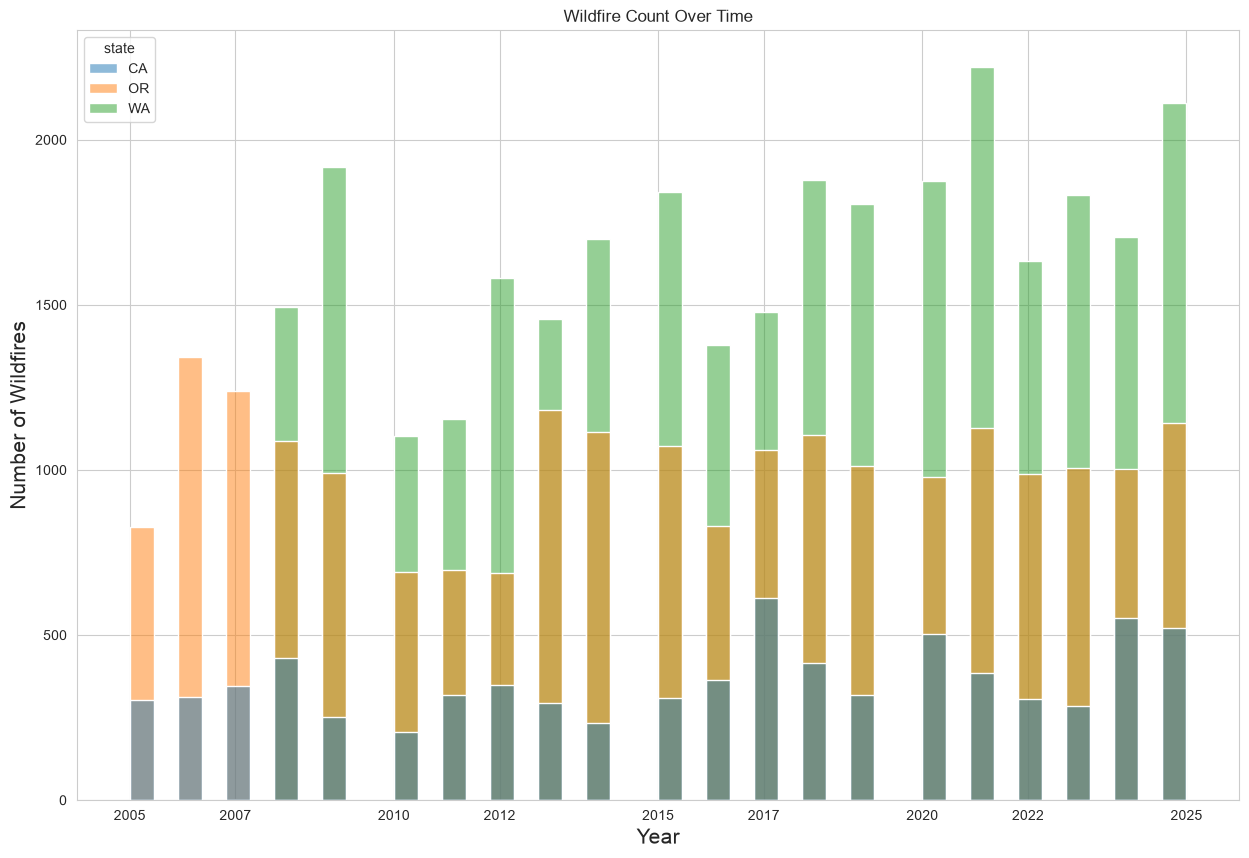

In [126]:
plt.figure(figsize=(15, 10))

sns.histplot(df, x='year', stat='count', hue='state')

plt.xlabel('Year', size=15)
plt.xticks(ticks=[ 2005.0, 2007.0, 2010.0, 2012.0, 2015.0, 2017.0, 2020.0, 2022.0, 2025.0], labels=["2005", "2007", "2010", "2012", "2015", "2017", "2020", "2022", "2025"])
plt.ylabel('Number of Wildfires', size=15)
plt.title('Wildfire Count Over Time')


plt.savefig('wildfire1.png', bbox_inches='tight')
plt.show()

In [109]:
monthly_aves = pd.DataFrame(df[['month', 'state']].value_counts())

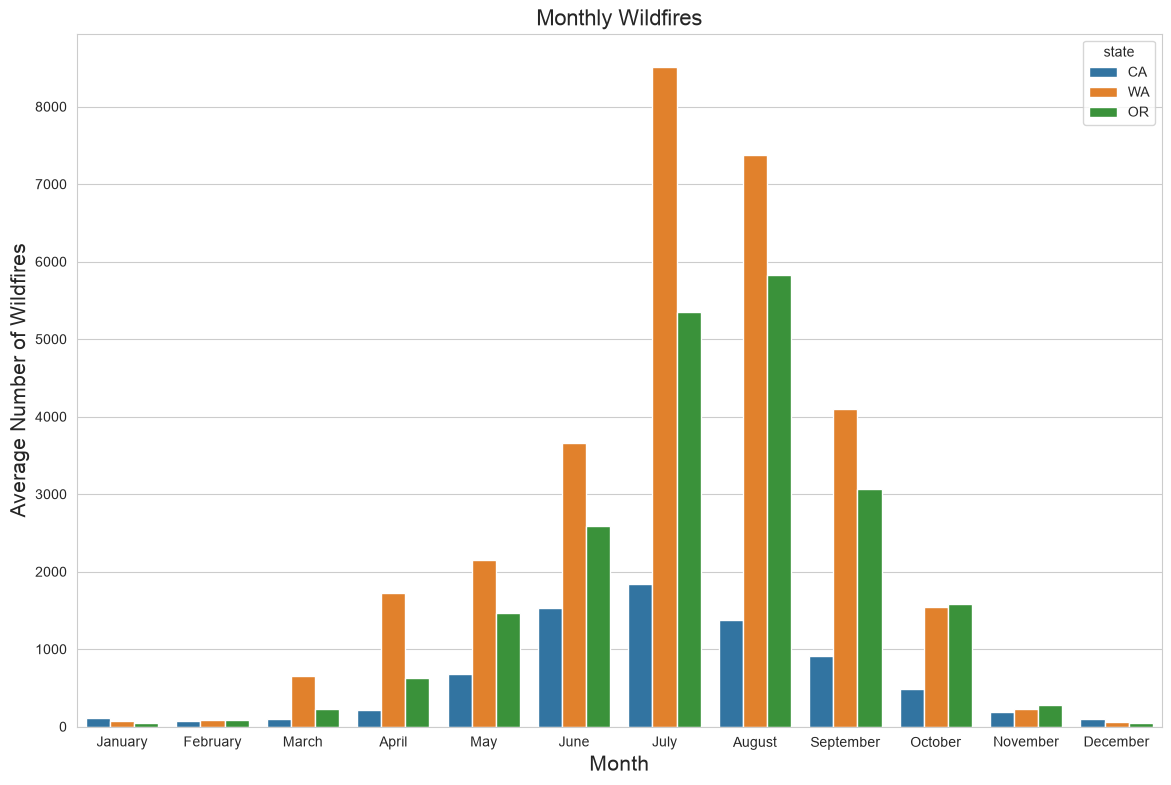

In [127]:
plt.figure(figsize=(14, 9))

sns.barplot(monthly_aves, x='month', y='count', hue='state')

plt.xlabel('Month', size=15)
plt.xticks(ticks=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
           labels=["January", "February", "March", "April", "May",
            "June", "July", "August", "September", "October", "November", "December"])
plt.ylabel('Average Number of Wildfires', size=15)
plt.title('Monthly Wildfires', size=16)

plt.savefig('wildfire2.png', bbox_inches='tight')
plt.show()

### By Cause

In [164]:
df['cause_catergory'].unique()

<ArrowStringArray>
[              'Debris',              'Unknown',                'Arson',
 'Equipment/Electrical',                'Human',        'Miscellaneous',
              'Natural']
Length: 7, dtype: str

In [158]:
yearly_cause = pd.DataFrame(df[['year', 'cause_catergory', 'state']].value_counts())

In [ ]:
yearly_cause

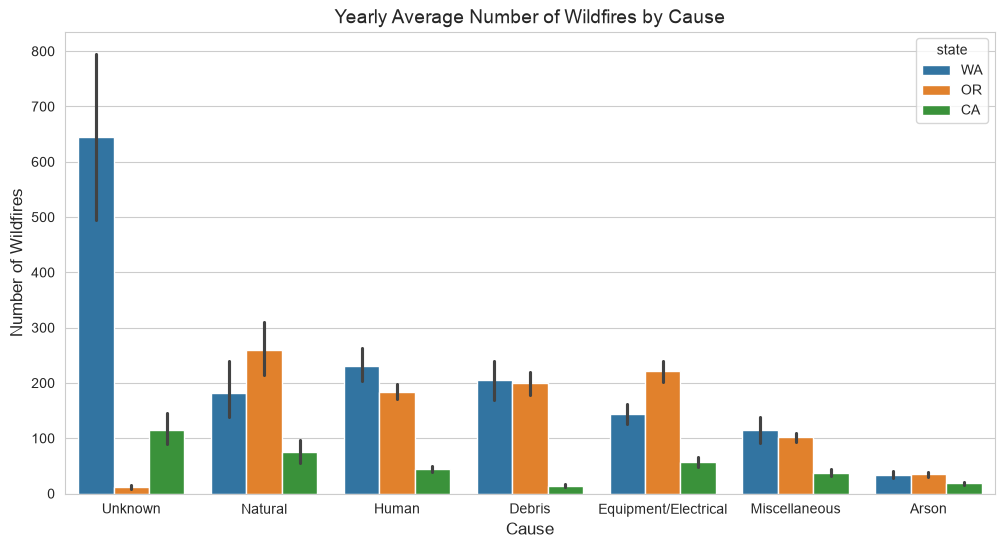

In [128]:
plt.figure(figsize=(12,6))

sns.barplot(data=yearly_cause, x="cause_catergory", y='count', estimator='mean', hue='state')

plt.xlabel('Cause', size=12)
plt.ylabel('Number of Wildfires', size=12)
plt.title('Yearly Average Number of Wildfires by Cause', size=14)

plt.savefig('wildfire3.png', bbox_inches='tight')
plt.show()

In [132]:
df.head()

,fire_id,date,month,year,state,county,longitude,latitude,cause_catergory,general_cause
0,7b26bbf8-4c41-454f-8861-5ae9343ce0ca,2005-03-15,3,2005,CA,Plumas,-120.212209,40.004125,Debris,Human
1,7f8df763-ba02-4d9c-a6aa-dbd0d248befb,2005-03-30,3,2005,CA,Inyo,-118.354929,37.394226,Unknown,Unspecified
2,3e54bc36-aa9b-4d76-a3eb-205ba388fbad,2005-04-07,4,2005,CA,Inyo,-118.337168,37.353866,Arson,Human
3,caec100b-7d1c-4374-8f25-3928214f6b21,2005-04-09,4,2005,CA,Riverside,-117.158041,33.847226,Unknown,Unspecified
4,a2689c74-b528-44d1-a3a5-7285836d32b4,2005-04-20,4,2005,CA,Riverside,-117.454492,33.872156,Equipment/Electrical,Human


In [166]:
general_cause = {'Unknown': 'Unspecified', 'Natural': 'Natural',
                 'Human': 'Human', 'Debris': 'Human',
                 'Equipment/Electrical': 'Human', 'Miscellaneous': 'Unspecified',
                'Arson': 'Human'}
df['general_cause'] = df['cause_catergory'].map(general_causes)

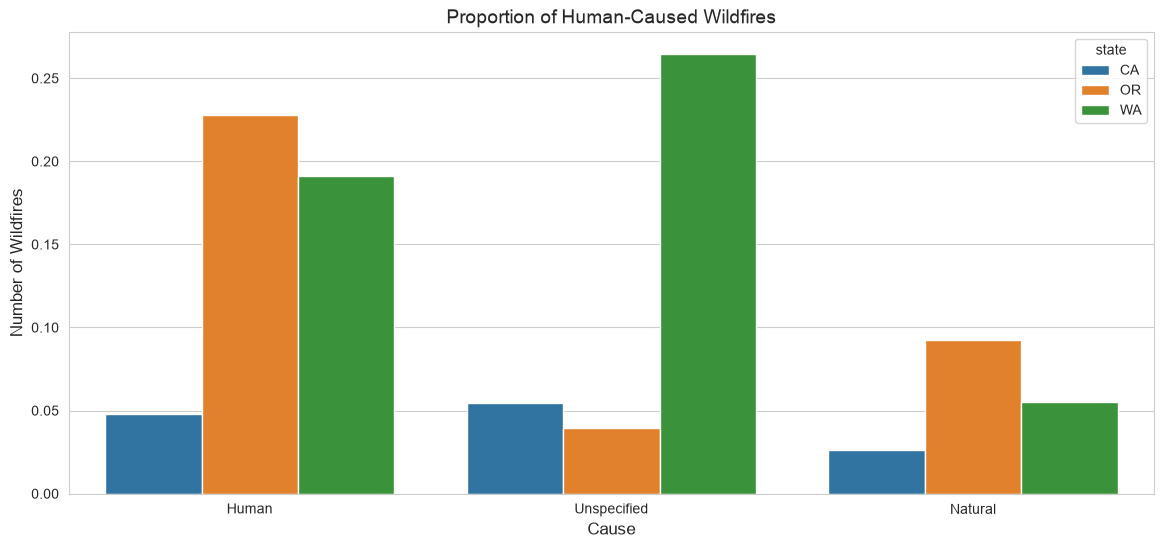

In [173]:
plt.figure(figsize=(14,6))

sns.countplot(df, x="general_cause", stat='proportion',hue='state')

plt.xlabel('Cause', size=12)
plt.ylabel('Number of Wildfires', size=12)
plt.title('Proportion of Human-Caused Wildfires', size=14)

plt.savefig('wildfire4.png', bbox_inches='tight')
plt.show()

### Burn Area Over time Visualizations

In [ ]:
plt.figure(figsize = (15, 8))
sns.barplot(df, x='year', y='acres_burned')

plt.xlabel('Year', fontsize=16)
plt.ylabel('Average Acres Burned', fontsize=16)
plt.title('Burn Area over time', fontsize=16)

plt.show()

In [ ]:
plt.figure(figsize=(8, 8))

sns.barplot(df, x='date', y='acres_burned', estimator='sum', hue='state')
plt.xlabel('Year')
plt.ylabel('Acres Burned')
plt.title('Wildfire Burn Area')

plt.savefig('wildfire_area_by_state.png', bbox_inches='tight')

plt.show()

In [ ]:
plt.figure(figsize = (15, 8))
sns.barplot(df, x='year', y='acres_burned', estimator='sum')

plt.xlabel('Year', fontsize=16)
plt.ylabel('Average Acres Burned', fontsize=16)
plt.title('Burn Area over time', fontsize=16)

plt.show()

In [ ]:
plt.figure(figsize = (15, 8))
ca_fire = df[df['state'] == 'CA']
sns.barplot(ca_fire, x='year', y='acres_burned')

plt.xlabel('Year', fontsize=16)
plt.ylabel('Average Acres Burned', fontsize=16)
plt.title('CA: Ave Burn Area Over Time', fontsize=16)

plt.show()

In [ ]:
plt.figure(figsize = (15, 8))
wa_fire = df[df['state'] == 'WA']
sns.barplot(wa_fire, x='year', y='acres_burned')

plt.xlabel('Year', fontsize=16)
plt.ylabel('Average Acres Burned', fontsize=16)
plt.title('WA: Ave Burn Area Over Time', fontsize=16)

plt.show()